<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/25_Backdoor_Trojan_Attacks_Against_QML/HybridQNN_BackdoorQcolor_Guo2024.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Backdoor attacks against hybrid classical-quantum neural networks (the Qcolor backdoor): Guo et al. step by step

This notebook re-implements, runs and checks the experiments of

> Ji Guo, Wenbo Jiang, Rui Zhang, Wenshu Fan, Jiachen Li and Guoming Lu,
> "Backdoor Attacks against Hybrid Classical-Quantum Neural Networks",
> arXiv:2407.16273 (July 2024); published in *Neural Networks* (2025), article 107776, DOI 10.1016/j.neunet.2025.107776.

The authors do not publish code, so everything below is written from the paper (Sections 4 to 6, Tables 1 to 8, Figures 3, 4, 6 to 12).

**What the notebook does.** A *hybrid quantum neural network* (HQNN) is a convolutional network (CNN) whose last layers are replaced by
a small variational quantum circuit (VQC). The notebook

1. downloads real image data (CIFAR-10 and MNIST) and shows it (dataset exploration),
2. builds the paper's HQNN: a CNN, then a **10-qubit, 6-layer VQC** that is simulated *exactly* (and checked, value and gradient, against a PennyLane QNode),
3. poisons a share of the training images with a trigger (Badnet patch, Blend, Color, WaNet and the paper's new **Qcolor** colour-shift trigger) and trains the victim,
4. measures clean accuracy, backdoor accuracy (BA) and attack success rate (ASR), compares the HQNN with a purely classical CNN (Table 1), tries to inject the backdoor into the quantum head only (Table 4),
5. finds the Qcolor channel ratios with a hand-written **NSGA-II** multi-objective optimiser (Algorithm 1), and re-runs Tables 5 to 8,
6. attacks the Qcolor model with the three defences of the paper (Fine-Pruning, STRIP, Neural Cleanse),
7. prints the paper's numbers next to ours with one verdict per claim.

**How to run it.** In Google Colab choose a CPU runtime and *Run all*. With `FAST_MODE = True` (default) it is a class demo (about 10 to 30 minutes on a free CPU
runtime; the committed run took 27 minutes on one heavily shared CPU thread); set `FAST_MODE = False` in the configuration cell for the larger budgets (see the runtime note there). No GPU, no account and no
quantum hardware are needed. The three datasets are public; a Hugging Face token is only used if you have one (see the imports cell).

**What you get at the end.** Executed tables that mirror Tables 1 to 8 of the paper, figures (dataset views, circuit drawings, trigger galleries,
NSGA-II front, defence plots), and an honest table "paper value / our value / verdict". The honest headline is already visible here: the *qualitative* findings are
tested on a much smaller, from-scratch network than the paper's pre-trained ResNets, so the absolute accuracies are far below the paper's.

## The paper in one page

**Problem.** Hybrid quantum-classical networks are popular because they need few qubits, but their security was unexplored. A *backdoor* (data-poisoning) attack inserts
training images carrying a secret **trigger** and relabels them to an attacker-chosen **target class**. The finished model behaves normally on clean inputs but sends every
triggered input to the target class.

**Threat model (Sec. 3).** The attacker only publishes a poisoned dataset; the victim trains the HQNN on it. The attacker knows nothing about the victim model and does not control training.
Goals: functionality preserving (clean accuracy stays), effective (high ASR) and stealthy (the triggered image looks like the clean one, measured by SSIM).

**Model (Sec. 6.1.2, Fig. 4).** `f_HQ(x) = f_Q(f_C(x))`: a ResNet-18 or ResNet-50 (ImageNet pre-trained) that produces features, then a 10-qubit VQC with six layers (H, RY rotations, CNOT gates), then a classifier.
The comparison model is the same ResNet with three ordinary fully connected layers (Table 2: 5120 / 100 / 100 parameters against 5120 / 60 / 100 for the HQNN).

**Theory (Sec. 4).** Theorem 1: the generalisation error on triggered samples is bounded below by a term that shrinks with the number *m* of poisoned samples and grows with the trigger strength.
Theorem 2: because of the *concentration of measure* in Hilbert space, a larger minimum perturbation is needed to move the feature distribution of an HQNN, so HQNNs should be harder to backdoor than CNNs.
(The proofs are in an appendix; nothing here can be rerun.)

**Experiments and claims.**
* Table 1 (Imagenette, poisoning rate 0.1): Badnet patches of 1 and 4 pixels and Blend ratios 0.05 and 0.1 fail completely against the HQNN (ASR 0.00) but succeed against the CNN (ASR 94 to 99); the HQNN is only broken by larger triggers (patch 9/16, ratio 0.15/0.2).
* Table 4: training only the VQC on top of a frozen clean CNN gives ASR 0.00, so the backdoor of an HQNN lives in the CNN features.
* **Qcolor backdoor (Sec. 5):** `I' = (R r1, G r2, B r3)`: a subtle global colour shift. The ratios (r1, r2, r3) are found with **NSGA-II** (Algorithm 1), trading effectiveness against SSIM.
* Table 5: Qcolor reaches ASR 99.80 to 99.95 on Imagenette, CIFAR-10 and MNIST with BA within one point of the clean accuracy. Table 6: ASR 98.75 % even at a poisoning rate of 1 %, where Blend, Badnet, WaNet and Color all have ASR 0. Table 7: ASR 99.0 to 99.97 for 1 to 6 VQC layers. Table 8: SSIM 99.9 % (same as Badnet, far above Blend 91.6, WaNet 91.7, Color 92.8).
* Figures 10 to 12: Qcolor survives Fine-Pruning (ASR always above BA), Neural Cleanse (anomaly index below 2) and STRIP (clean and triggered entropy distributions look alike).

**Data (Sec. 6.1.1).** MNIST (60k/10k), CIFAR-10 (50k/10k), Imagenette (1000/400 per class), all resized to 224 x 224 x 3, 10 classes each.

## What follows the paper and what had to be chosen

The paper's main experiments need two ImageNet-pre-trained ResNets on 224 x 224 images, i.e. GPU hours per model and dozens of models. A free Colab CPU cannot do that,
so this notebook keeps the **experimental design and the quantum circuit** and shrinks the **classical network and the images**. Every choice is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Datasets | MNIST, CIFAR-10, Imagenette at 224 x 224 x 3 | **CIFAR-10 and MNIST** at 32 x 32 x 3 (MNIST: bilinear resize, grey replicated on 3 channels). Imagenette is not used (224-px images are too heavy). Real images from Hugging Face parquet mirrors (`uoft-cs/cifar10`, `ylecun/mnist`): a class-balanced pool of 12,000 train / 3,000 test images per dataset, of which `N_TRAIN` / `N_TEST` are used |
| Classical part | ResNet-18 / ResNet-50, ImageNet pre-trained | `# CHOICE:` a small ResNet (stem + three residual blocks, 64 output features, trained **from scratch**), the same trunk for the HQNN and the CNN baseline |
| Quantum part | 10 qubits, six-layer VQC (Fig. 4: H, RY, CNOT) | 10 qubits, 6 layers. `# CHOICE:` H on all qubits, RY(x_i) data encoding, then 6 x [CNOT ring, RY(w) on every qubit], read-out of all ten Pauli-Z expectation values (60 trainable angles, as in Table 2) |
| Interface layers | FC 512 -> 10 (5120 params), VQC, FC 10 -> 10 | `# CHOICE:` Linear(64, 10), angles = tanh(.) x pi/2, VQC, Linear(10, 10). The classical comparison model has Linear(64,10), Linear(10,10), Linear(10,10) |
| Quantum simulation | not stated | exact differentiable state-vector simulator in torch; the notebook **asserts** that it equals a PennyLane QNode of the same circuit (values and gradients) |
| Optimisation | not stated | `# CHOICE:` Adam, lr 2e-3 (x10 for the circuit angles), cosine schedule, batch 64, `EPOCHS` epochs, cross-entropy |
| Poisoning | rate 0.1; triggered images of non-target classes are added | `# CHOICE:` BadNets-style dirty labels: a fraction of the **non-target** training images is replaced by its triggered version and labelled with the target class; target class 0 |
| Badnet / Blend | patch 1, 4, 9, 16; blend ratio 0.05 to 0.2 | `# CHOICE:` patch 1 to 4 px (the images are 7 x smaller), blend ratios as in the paper with one fixed random-noise pattern |
| Trigger strengths in Tables 6 and 8 | "the lowest parameters that attack successfully" | chosen automatically from our Table 1 (smallest setting with HQNN ASR >= 80 %) |
| Color / WaNet | cited methods | `# CHOICE:` Color: one fixed colour layer, alpha 0.2; WaNet: k = 4, s = 0.5, without the noise mode |
| Qcolor ratios | NSGA-II on Eq. 18 | own NSGA-II (Algorithm 1), ratios in [0.5, 1.5], two objectives `f1 = (1 - BA) + (1 - ASR)` and `f2 = 1 - SSIM`; a candidate is scored by a short training run and measured on the **validation** split |
| Metrics | CA, BA, ASR (target-class samples excluded), SSIM | the same; SSIM implemented in torch (11 x 11 Gaussian window) |
| Defences | STRIP, Neural Cleanse, Fine-Pruning | compact re-implementations on our model (Fine-Pruning without the fine-tuning step, Neural Cleanse with a fixed L1 weight and few steps) |
| Seeds | not stated | `SEED = 42`; the headline Table 5 rows use the seeds in `SEEDS_HEADLINE` |
| Theory (Theorems 1, 2) | proofs | not rerunnable; only the qualitative trend "more poisoned samples, higher ASR" is looked at |

## 0. Setup

The next cell installs the pinned libraries that Colab does not ship (PennyLane for drawing and checking the circuit). It does nothing if they are already present. If Colab asks you to restart the session after the installation, do so and run all cells again.

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships torch, numpy, pandas, scikit-learn, matplotlib, pillow, pyarrow.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    %pip install -q "pennylane==0.45.1" huggingface_hub pyarrow
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("pennylane already present; skipping pip install.")


pennylane already present; skipping pip install.


### Configuration

Every tunable number lives in this one cell. `FAST_MODE = True` is the class demo. `FAST_MODE = False` uses 5,000 training images, 6 epochs, four patch sizes,
four blend ratios, four poisoning rates, three circuit depths and a larger NSGA-II budget; on a 2-core CPU that is roughly an hour or more (see the timing printed at the very end of the executed notebook).
`IBM_TOKEN` is unused: the 10-qubit circuit is simulated exactly, no hardware is needed.

**Note on the executed outputs.** The outputs stored in this notebook come from one complete `FAST_MODE = True` run (27 minutes, 1 CPU thread on a heavily shared machine). The larger-budget path (`FAST_MODE = False`) was started but not completed in local validation because its projected run time (about 2 hours on that machine) exceeded the time limit; its budgets are documented above and in the code, and the code path is identical.

In [2]:
# ---------------- configuration ----------------
import time; T_START = time.time()
FAST_MODE = True            # True: class demo (10 to 25 minutes on a free 2-core CPU). False: the larger budgets below (roughly 1 to 2 hours).
SEED      = 42              # CHOICE: the paper gives no seed
IBM_TOKEN = ""              # not used: the quantum circuit is simulated exactly, no hardware is needed
DATA_DIR  = "data"          # cache for the downloaded image subsets
N_QUBITS, N_LAYERS = 10, 6  # paper Sec. 6.1.2: 10 qubits, six-layer VQC
N_CLASSES, TARGET = 10, 0   # CHOICE: the attack target class is class 0 (CIFAR-10 'airplane', MNIST digit 0)
POOL_TRAIN, POOL_TEST, N_VAL = 12000, 3000, 1000   # size of the cached, class-balanced real-image pool per dataset

if FAST_MODE:
    N_TRAIN, N_TEST = 3000, 1000            # images actually used for training / testing
    EPOCHS          = 4
    PATCH_SIZES     = [1, 4]                # Table 1 patch sizes   (px on a 32 x 32 image)
    BLEND_RATIOS    = [0.05, 0.2]           # Table 1 blend ratios
    POISON_RATES    = [0.10, 0.02]          # Table 6 poisoning rates
    LAYER_LIST      = [1, 6]                # Table 7 VQC depths
    NSGA_POP, NSGA_GEN, NSGA_EPOCHS, NSGA_TRAIN = 6, 2, 2, 1500
    NC_STEPS, STRIP_N, STRIP_SAMPLES = 40, 20, 150
    SEEDS_HEADLINE  = [SEED]
else:
    N_TRAIN, N_TEST = 5000, 2000
    EPOCHS          = 6
    PATCH_SIZES     = [1, 2, 3, 4]
    BLEND_RATIOS    = [0.05, 0.10, 0.15, 0.20]
    POISON_RATES    = [0.10, 0.04, 0.02, 0.01]
    LAYER_LIST      = [1, 3, 6]
    NSGA_POP, NSGA_GEN, NSGA_EPOCHS, NSGA_TRAIN = 8, 3, 2, 3000
    NC_STEPS, STRIP_N, STRIP_SAMPLES = 150, 50, 300
    SEEDS_HEADLINE  = [SEED, SEED + 1]      # headline Table 5 rows: mean +- std over two seeds
BATCH, LR = 64, 2e-3                        # CHOICE: Adam, lr 2e-3 (the paper gives no optimiser settings)
POISON_MAIN = 0.10                          # paper Sec. 6.1.3: poisoning rate 0.1
print("FAST_MODE =", FAST_MODE, "| train/test images:", N_TRAIN, N_TEST, "| epochs:", EPOCHS)


FAST_MODE = True | train/test images: 3000 1000 | epochs: 4


### Imports, seeds and library versions

All random generators are seeded (`torch`, `numpy`, per-run generators for shuffling and poisoning). A Hugging Face token, if you have one, is read from the environment or from Colab Secrets (`HF_TOKEN`) and never printed; the three datasets used here are public, so no token is required.

In [3]:
import os, io, time, copy, warnings, itertools, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import sklearn
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

import torch, torch.nn as nn, torch.nn.functional as F
import pennylane as qml
from PIL import Image

NUM_THREADS = int(os.environ.get("NUM_THREADS", max(1, min(2, os.cpu_count() or 1))))   # 2 CPU threads (Colab has 2 vCPUs)
torch.set_num_threads(NUM_THREADS)
torch.manual_seed(SEED); np.random.seed(SEED)
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

# Hugging Face token: only needed if a dataset is gated (the three used here are public). Never printed.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata            # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

print("torch", torch.__version__, "| pennylane", qml.__version__, "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__, "| threads", NUM_THREADS)


torch 2.14.1+cpu | pennylane 0.45.1 | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | threads 1


## 1. The data: real CIFAR-10 and MNIST images

The paper uses three 10-class image sets. We use two of them and say so in the table above. The images are downloaded once from the public Hugging Face parquet mirrors
(`uoft-cs/cifar10`, `ylecun/mnist`), decoded, sampled **class-balanced** with a fixed seed into a pool of 12,000 training and 3,000 test images, cached in `DATA_DIR` as a small `.npz`,
and the big parquet file is deleted again. The first `N_TRAIN` pool images are the training set, the last `N_VAL` training-pool images the **validation** set (used only to choose Qcolor ratios and to rank pruning candidates),
the first `N_TEST` test-pool images the test set. All pixel values are scaled to [0, 1]; a trigger acts on these values.

In [4]:
CIFAR_CLASSES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
MNIST_CLASSES = [str(d) for d in range(10)]

def _decode(col):
    """parquet image column (dicts with PNG bytes) -> uint8 array (N, H, W[, 3])"""
    return np.stack([np.array(Image.open(io.BytesIO(d["bytes"]))) for d in col])

def _balanced_pick(y, per_class, r):
    idx = np.concatenate([r.choice(np.flatnonzero(y == c), per_class, replace=False) for c in range(10)])
    return r.permutation(idx)

def load_image_pool(name):
    """Return (x_train, y_train, x_test, y_test) as uint8 pools of 12000 / 3000 class-balanced REAL images.
    Source: Hugging Face parquet mirrors (uoft-cs/cifar10, ylecun/mnist). Cached in DATA_DIR; big parquet files are deleted after reading."""
    cache = os.path.join(DATA_DIR, f"{name}_pool.npz")
    if os.path.exists(cache):
        try:
            d = np.load(cache); return d["xtr"], d["ytr"], d["xte"], d["yte"]
        except Exception:
            os.remove(cache)
    from huggingface_hub import hf_hub_download
    repo, files, icol = {"cifar10": ("uoft-cs/cifar10", ("plain_text/train-00000-of-00001.parquet", "plain_text/test-00000-of-00001.parquet"), "img"),
                         "mnist": ("ylecun/mnist", ("mnist/train-00000-of-00001.parquet", "mnist/test-00000-of-00001.parquet"), "image")}[name]
    r = np.random.default_rng(SEED)
    out = []
    for f, per_class in zip(files, (POOL_TRAIN // 10, POOL_TEST // 10)):
        p = hf_hub_download(repo_id=repo, filename=f, repo_type="dataset", local_dir=os.path.join(DATA_DIR, "hf_" + name), token=HF_TOKEN)
        df = pd.read_parquet(p)
        y = df["label"].to_numpy().astype(int)
        idx = _balanced_pick(y, per_class, r)
        out += [_decode(df[icol].iloc[idx]), y[idx]]
        del df
        if os.path.getsize(p) > 50e6: os.remove(p)                # keep the disk footprint small
    np.savez_compressed(cache, xtr=out[0], ytr=out[1], xte=out[2], yte=out[3])
    return out[0], out[1], out[2], out[3]

def to_tensor32(x):
    """uint8 (N,H,W[,3]) -> float32 (N,3,32,32) in [0,1]. MNIST: 28x28 grey -> bilinear resize to 32x32, replicated on 3 channels (as the paper's 3-channel resize)."""
    t = torch.from_numpy(x).float() / 255.0
    t = t.unsqueeze(1).repeat(1, 3, 1, 1) if t.ndim == 3 else t.permute(0, 3, 1, 2)
    if t.shape[-1] != 32: t = F.interpolate(t, size=32, mode="bilinear", align_corners=False)
    return t.contiguous()

DATA = {}
for ds in ("cifar10", "mnist"):
    t0 = time.time()
    xtr, ytr, xte, yte = load_image_pool(ds)
    X = to_tensor32(xtr); Y = torch.from_numpy(ytr).long()
    XT = to_tensor32(xte); YT = torch.from_numpy(yte).long()
    DATA[ds] = dict(raw_tr=xtr, raw_te=xte, ytr_all=ytr, yte_all=yte,
                    x_train=X[:N_TRAIN], y_train=Y[:N_TRAIN], x_val=X[-N_VAL:], y_val=Y[-N_VAL:],
                    x_test=XT[:N_TEST], y_test=YT[:N_TEST],
                    classes=CIFAR_CLASSES if ds == "cifar10" else MNIST_CLASSES)
    d = DATA[ds]
    print(f"{ds:8s}: pool {xtr.shape} / {xte.shape} -> train {tuple(d['x_train'].shape)}, val {tuple(d['x_val'].shape)}, test {tuple(d['x_test'].shape)}  ({time.time()-t0:.0f} s)")
assert N_TRAIN + N_VAL <= POOL_TRAIN and N_TEST <= POOL_TEST      # train = pool[:N_TRAIN], validation = pool[-N_VAL:]: disjoint


cifar10 : pool (12000, 32, 32, 3) / (3000, 32, 32, 3) -> train (3000, 3, 32, 32), val (1000, 3, 32, 32), test (1000, 3, 32, 32)  (1 s)


mnist   : pool (12000, 28, 28) / (3000, 28, 28) -> train (3000, 3, 32, 32), val (1000, 3, 32, 32), test (1000, 3, 32, 32)  (2 s)


## Dataset Exploration and Visualisation

Everything in this section is computed from the real images the experiments use. First the shapes, the feature names (3,072 pixel intensities) and the original label values with class counts;
then the real class distribution, a gallery of real images, and 2-D scatter plots in which every point is one real image coloured by its ground-truth class: the raw PCA coordinates (PCA fitted on the training split only),
then the same coordinates scaled to the rotation-angle range [0, pi] that a quantum circuit with angle encoding works in. Both datasets have ten classes and we keep all ten (colour = class, not just "target / not target").

== CIFAR10 ==
  cached real-image pool : train (12000, 32, 32, 3) | test (3000, 32, 32, 3) (uint8)
  used here              : x_train (3000, 3, 32, 32) x_val (1000, 3, 32, 32) x_test (1000, 3, 32, 32) (float32, 3 x 32 x 32, values in [0, 1])
  features               : 3 x 32 x 32 = 3072 pixel intensities; names r0..r1023, g0..g1023, b0..b1023 (channel-major)
  original label values  : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] -> ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


,airplane,automobile,bird,cat,deer,dog,frog,horse,ship,truck
train,307,311,282,292,292,284,332,289,305,306
validation,104,94,100,94,104,106,88,113,108,89
test,102,107,101,97,98,97,93,100,94,111


== MNIST ==
  cached real-image pool : train (12000, 28, 28) | test (3000, 28, 28) (uint8)
  used here              : x_train (3000, 3, 32, 32) x_val (1000, 3, 32, 32) x_test (1000, 3, 32, 32) (float32, 3 x 32 x 32, values in [0, 1])
  features               : 3 x 32 x 32 = 3072 pixel intensities; names r0..r1023, g0..g1023, b0..b1023 (channel-major)
  original label values  : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] -> ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']


,0,1,2,3,4,5,6,7,8,9
train,307,311,282,292,292,284,332,289,305,306
validation,104,94,100,94,104,106,88,113,108,89
test,102,107,101,97,98,97,93,100,94,111


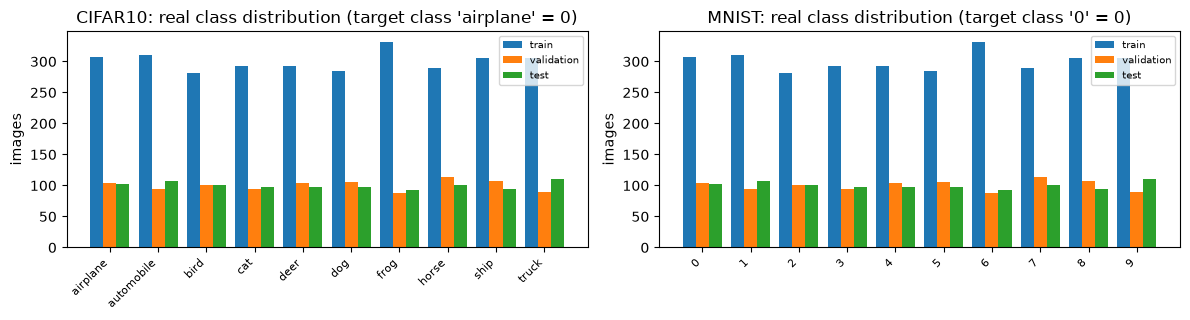

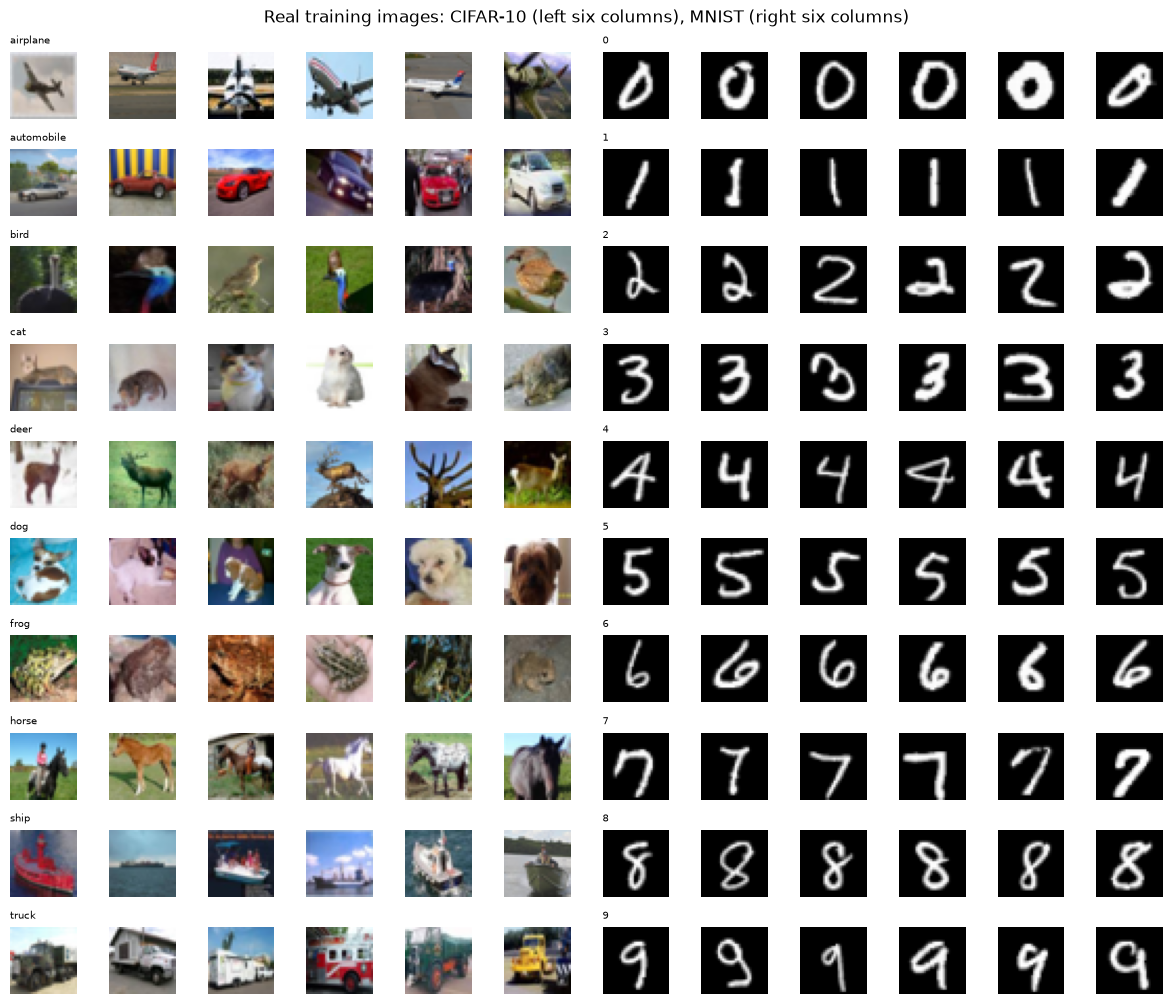

In [5]:
### 1. Shape, features, labels, class counts (real images only)
for ds in ("cifar10", "mnist"):
    d = DATA[ds]
    print(f"== {ds.upper()} ==")
    print("  cached real-image pool : train", d["raw_tr"].shape, "| test", d["raw_te"].shape, "(uint8)")
    print("  used here              : x_train", tuple(d["x_train"].shape), "x_val", tuple(d["x_val"].shape), "x_test", tuple(d["x_test"].shape), "(float32, 3 x 32 x 32, values in [0, 1])")
    print("  features               : 3 x 32 x 32 = 3072 pixel intensities; names r0..r1023, g0..g1023, b0..b1023 (channel-major)")
    print("  original label values  :", sorted(np.unique(d["ytr_all"]).tolist()), "->", d["classes"])
    cnt = pd.DataFrame({"train": np.bincount(d["y_train"].numpy(), minlength=10), "validation": np.bincount(d["y_val"].numpy(), minlength=10),
                        "test": np.bincount(d["y_test"].numpy(), minlength=10)}, index=d["classes"])
    display(cnt.T)

### 2. Real class distribution
fig, axs = plt.subplots(1, 2, figsize=(12, 3.3))
for ax, ds in zip(axs, ("cifar10", "mnist")):
    d = DATA[ds]; w = 0.27
    for k, (nm, key) in enumerate((("train", "y_train"), ("validation", "y_val"), ("test", "y_test"))):
        ax.bar(np.arange(10) + (k - 1) * w, np.bincount(d[key].numpy(), minlength=10), width=w, label=nm)
    ax.set_xticks(range(10)); ax.set_xticklabels(d["classes"], rotation=45, ha="right", fontsize=8)
    ax.set_title(f"{ds.upper()}: real class distribution (target class '{d['classes'][TARGET]}' = {TARGET})"); ax.set_ylabel("images"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

### 3. Gallery of real images (first 6 per class, CIFAR-10 left / MNIST right)
fig, axs = plt.subplots(10, 12, figsize=(12, 10.2))
for j, ds in enumerate(("cifar10", "mnist")):
    d = DATA[ds]
    for c in range(10):
        ids = np.flatnonzero(d["y_train"].numpy() == c)[:6]
        for k, i in enumerate(ids):
            ax = axs[c, 6 * j + k]; ax.imshow(d["x_train"][i].permute(1, 2, 0).numpy()); ax.axis("off")
        axs[c, 6 * j].set_title(d["classes"][c], fontsize=7, loc="left")
plt.suptitle("Real training images: CIFAR-10 (left six columns), MNIST (right six columns)"); plt.tight_layout(); plt.show()


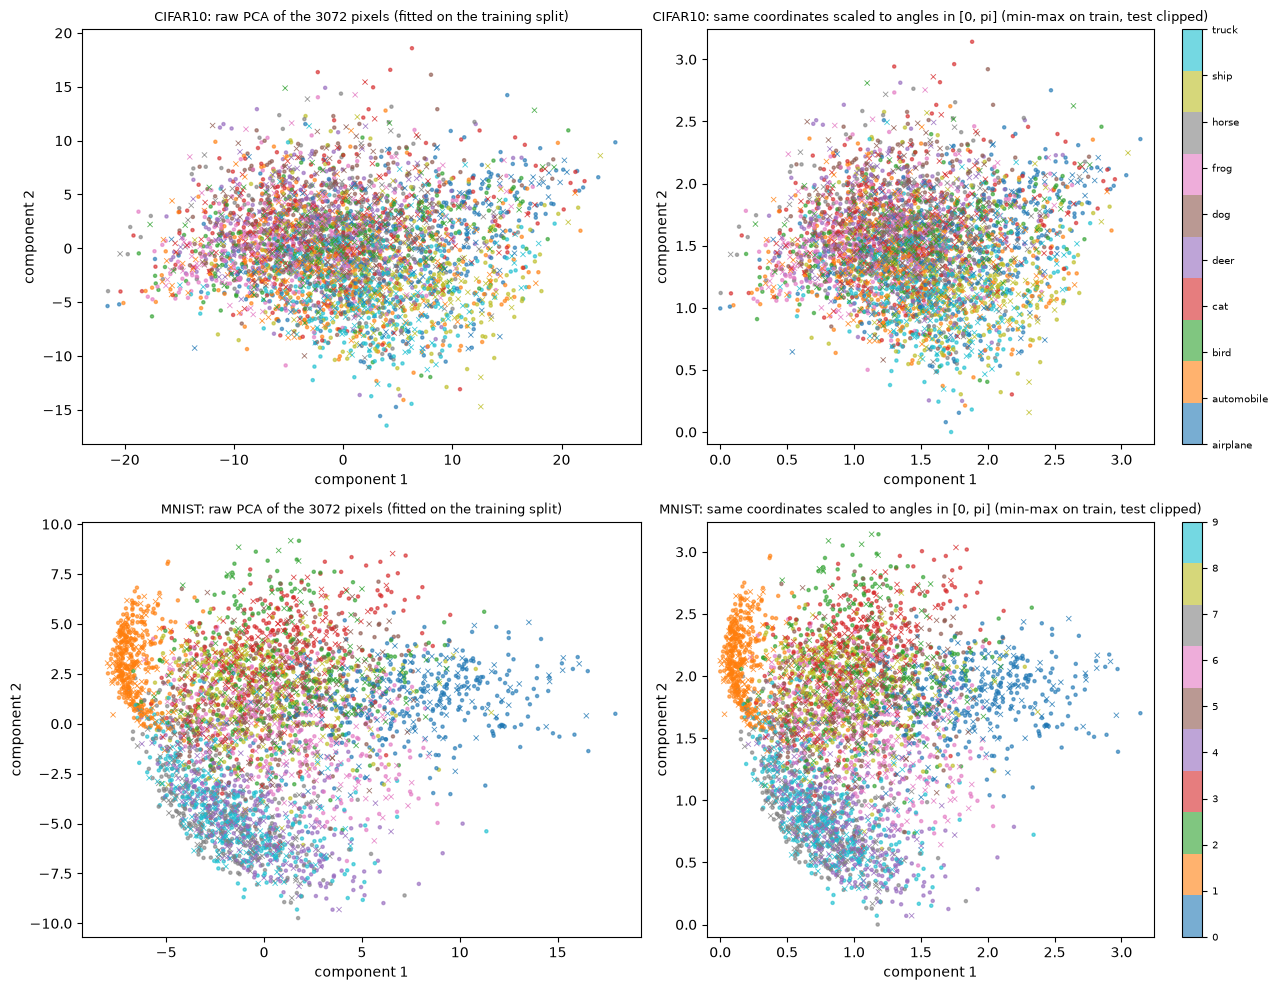

Every point above is one real training image coloured by its ground-truth class. CIFAR-10 classes overlap heavily in a linear 2-D view;
the digits of MNIST form clearer clusters. The CNN in front of the circuit learns a much better 10-D feature map than these 2-D projections.


In [6]:
### 4. Real observations in 2-D coloured by ground truth: raw PCA, then the same coordinates scaled to [0, pi]
def pca_views(ds):
    d = DATA[ds]
    Xtr = d["x_train"].flatten(1).numpy(); Xte = d["x_test"].flatten(1).numpy()
    pca = PCA(n_components=2, random_state=SEED).fit(Xtr)                          # fitted on the training split only
    ztr, zte = pca.transform(Xtr), pca.transform(Xte)
    mm = MinMaxScaler((0, np.pi)).fit(ztr)                                         # the VQC works with rotation angles
    return ztr, zte, mm.transform(ztr), np.clip(mm.transform(zte), 0, np.pi)

fig, axs = plt.subplots(2, 2, figsize=(13, 10))
for row, ds in enumerate(("cifar10", "mnist")):
    d = DATA[ds]; ztr, zte, atr, ate = pca_views(ds)
    for col, (A, Bt, ttl) in enumerate(((ztr, zte, "raw PCA of the 3072 pixels (fitted on the training split)"),
                                        (atr, ate, "same coordinates scaled to angles in [0, pi] (min-max on train, test clipped)"))):
        ax = axs[row, col]
        sc = ax.scatter(A[:, 0], A[:, 1], c=d["y_train"].numpy(), cmap="tab10", s=5, alpha=.6)
        ax.scatter(Bt[:, 0], Bt[:, 1], c=d["y_test"].numpy(), cmap="tab10", s=14, marker="x", linewidths=.6, alpha=.8)
        ax.set_title(f"{ds.upper()}: {ttl}", fontsize=9); ax.set_xlabel("component 1"); ax.set_ylabel("component 2")
        if col == 1: ax.set_xlim(-.1, np.pi + .1); ax.set_ylim(-.1, np.pi + .1)
    cb = plt.colorbar(sc, ax=axs[row, 1]); cb.set_ticks(range(10)); cb.set_ticklabels(d["classes"]); cb.ax.tick_params(labelsize=7)
plt.tight_layout(); plt.show()
print("Every point above is one real training image coloured by its ground-truth class. CIFAR-10 classes overlap heavily in a linear 2-D view;")
print("the digits of MNIST form clearer clusters. The CNN in front of the circuit learns a much better 10-D feature map than these 2-D projections.")


## 2. The hybrid network and its circuit

**Classical part.** A small residual network turns a 3 x 32 x 32 image into 64 numbers (global average pooling). It plays the role of the paper's ResNet-18/50.

**Interface.** `Linear(64, 10)` followed by `tanh(.) x pi/2` produces **ten rotation angles**, one per qubit (the "dressed quantum circuit" of Mari et al., the transfer-learning scheme the paper cites for its model).

**Quantum part.** The ten angles are written into ten qubits, six trainable layers act on them, and the ten Pauli-Z expectation values (numbers in [-1, 1]) come out; `Linear(10, 10)` turns them into class scores.

**Exact simulation.** Gate-by-gate state-vector simulation of 10 qubits is slow in Python, so the circuit is written as batched matrix products in torch. All gates (H, RY, CNOT) are real, so the state stays real
and the simulator is exact and differentiable. The next section **proves on the spot** that this simulator equals PennyLane's QNode of the same circuit, both in output and in gradient.

In [7]:
# ---------- exact state-vector simulator of the paper's VQC, written in torch so that it is differentiable ----------
# Circuit (CHOICE: the paper only shows Fig. 4 as a picture): H on all qubits, RY(x_i) data encoding, then L layers of
# [ring of CNOTs, RY(w_li) on every qubit]; measurement: <Z_i> of every qubit.  All gates are real, so the state stays real.
def _cnot_ring_perm(n):
    """Basis-state permutation of the CNOT ring CNOT(0->1), CNOT(1->2), ..., CNOT(n-1->0). Qubit 0 is the most significant bit."""
    f = np.arange(2 ** n)
    for i in range(n):
        c, t = i, (i + 1) % n
        bit_c = (f >> (n - 1 - c)) & 1
        f = f ^ (bit_c << (n - 1 - t))
    inv = np.empty_like(f); inv[f] = np.arange(2 ** n)       # new_state[f(s)] = state[s]
    return torch.from_numpy(inv).long()

def _ry_mats(c, s):
    """c, s: (..., n) cos/sin of half angles -> (..., n, 2, 2) matrices RY = [[c, -s], [s, c]]."""
    return torch.stack([torch.stack([c, -s], -1), torch.stack([s, c], -1)], -2)

def _kron_chain(m):
    """m: (..., k, 2, 2) single-qubit matrices -> (..., 2^k, 2^k) Kronecker product, first qubit = most significant."""
    K = m[..., 0, :, :]
    for q in range(1, m.shape[-3]):
        a = m[..., q, :, :]
        K = (K[..., :, None, :, None] * a[..., None, :, None, :]).reshape(*K.shape[:-2], K.shape[-2] * 2, K.shape[-1] * 2)
    return K

class TorchVQC(nn.Module):
    """Exact, batched, differentiable state-vector simulation of the circuit. A layer of single-qubit RY gates is applied as two
    small matrix products (qubits 0..4 and 5..9 are grouped) instead of ten separate gates, which keeps the CPU cost low."""
    def __init__(self, n_qubits=N_QUBITS, n_layers=N_LAYERS):
        super().__init__()
        self.n, self.L = n_qubits, n_layers
        self.n1 = n_qubits // 2
        self.weights = nn.Parameter(torch.rand(n_layers, n_qubits) * 2 * math.pi)     # CHOICE: uniform [0, 2 pi) initialisation
        self.register_buffer("perm", _cnot_ring_perm(n_qubits))
        idx = torch.arange(2 ** n_qubits)
        self.register_buffer("zsign", torch.stack([1 - 2 * ((idx >> (n_qubits - 1 - q)) & 1) for q in range(n_qubits)], 1).float())

    def _apply_ry_layer(self, psi, c, s):
        """psi: (B, 2^n); c, s: (n,) or (B, n). Returns RY(theta_0) x ... x RY(theta_{n-1}) applied to every state."""
        M = _ry_mats(c, s); Ka, Kb = _kron_chain(M[..., :self.n1, :, :]), _kron_chain(M[..., self.n1:, :, :])
        B = psi.shape[0]; psi = psi.reshape(B, 2 ** self.n1, 2 ** (self.n - self.n1))
        psi = torch.matmul(Ka, psi)                                      # qubits 0 .. n1-1
        psi = torch.matmul(psi, Kb.transpose(-1, -2) if Kb.ndim == 2 else Kb.transpose(-1, -2))   # qubits n1 .. n-1
        return psi.reshape(B, -1)

    def forward(self, x):                                   # x: (B, n) encoding angles
        B = x.shape[0]
        psi = x.new_full((B, 2 ** self.n), 2.0 ** (-self.n / 2))             # H^n |0...0>
        psi = self._apply_ry_layer(psi, torch.cos(x / 2), torch.sin(x / 2))  # RY(x_i) data encoding
        wc, ws = torch.cos(self.weights / 2), torch.sin(self.weights / 2)
        for l in range(self.L):
            psi = psi[:, self.perm]                                          # CNOT ring
            psi = self._apply_ry_layer(psi, wc[l], ws[l])                    # trainable RY layer
        return (psi ** 2) @ self.zsign                                       # (B, n) values <Z_q> in [-1, 1]
# ---------- PennyLane QNode of exactly the same circuit (used to draw it and to check the simulator) ----------
def make_qnode(n_qubits=N_QUBITS, n_layers=N_LAYERS):
    dev = qml.device("default.qubit", wires=n_qubits)
    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def vqc_qnode(x, w):
        for q in range(n_qubits): qml.Hadamard(wires=q)
        qml.AngleEmbedding(x, wires=range(n_qubits), rotation="Y")
        for l in range(n_layers):
            for q in range(n_qubits): qml.CNOT(wires=[q, (q + 1) % n_qubits])
            for q in range(n_qubits): qml.RY(w[l, q], wires=q)
        return [qml.expval(qml.PauliZ(q)) for q in range(n_qubits)]
    return vqc_qnode

# ---------- the classical part: a small ResNet (CHOICE: stands in for ResNet-18/50, see the table above) ----------
class ResBlock(nn.Module):
    def __init__(self, cin, cout, stride):
        super().__init__()
        self.c1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False); self.b1 = nn.BatchNorm2d(cout)
        self.c2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False);    self.b2 = nn.BatchNorm2d(cout)
        self.sc = None if (stride == 1 and cin == cout) else nn.Sequential(nn.Conv2d(cin, cout, 1, stride, bias=False), nn.BatchNorm2d(cout))
    def forward(self, x):
        y = self.b2(self.c2(F.relu(self.b1(self.c1(x)))))
        return F.relu(y + (x if self.sc is None else self.sc(x)))

class MiniResNet(nn.Module):
    """3x32x32 -> 64 features (global average pooling). The stem has stride 2 to keep the CPU cost small. Blocks: .stem, .s1, .s2, .s3."""
    def __init__(self, width=16):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, width, 3, 2, 1, bias=False), nn.BatchNorm2d(width), nn.ReLU())
        self.s1, self.s2, self.s3 = ResBlock(width, width, 1), ResBlock(width, 2 * width, 2), ResBlock(2 * width, 4 * width, 2)
        self.out_dim = 4 * width
    def forward(self, x):
        return F.adaptive_avg_pool2d(self.s3(self.s2(self.s1(self.stem(x)))), 1).flatten(1)

class HybridNet(nn.Module):
    """kind='hybrid' (HQNN): CNN -> Linear(64,10) -> tanh*pi/2 -> VQC(10 qubits) -> Linear(10,10).   [paper Table 2: FC1 / VQC / FC3]
       kind='cnn'            : CNN -> Linear(64,10) -> ReLU -> Linear(10,10) -> ReLU -> Linear(10,10).  [paper Table 2: 3 FC layers]"""
    def __init__(self, kind="hybrid", n_layers=N_LAYERS):
        super().__init__()
        self.kind = kind
        self.cnn = MiniResNet()
        self.fc1 = nn.Linear(self.cnn.out_dim, N_QUBITS)
        if kind == "hybrid":
            self.vqc = TorchVQC(N_QUBITS, n_layers); self.fc2 = None
        else:
            self.vqc = None; self.fc2 = nn.Linear(N_QUBITS, N_QUBITS)
        self.fc3 = nn.Linear(N_QUBITS, N_CLASSES)
    def angles(self, x):
        return torch.tanh(self.fc1(self.cnn(x))) * (math.pi / 2)         # the 10 qubit rotation angles (Mari et al. 2020)
    def head(self, f):
        if self.kind == "hybrid": return self.fc3(self.vqc(torch.tanh(self.fc1(f)) * (math.pi / 2)))
        return self.fc3(F.relu(self.fc2(F.relu(self.fc1(f)))))
    def forward(self, x):
        return self.head(self.cnn(x))


## Quantum Circuit Architecture

The circuit is the one the paper describes in Section 6.1.2 and Fig. 4 (10 qubits, six layers, Hadamard, RY and CNOT gates). The paper shows it only as a picture, so the exact gate order is a **documented assumption**:

1. `H` on every qubit (a uniform superposition), then `RY(x_i)` on qubit *i* with the angle produced by the CNN (**data encoding**),
2. six times: a ring of **CNOT** gates `0->1, 1->2, ..., 9->0` (entanglement) followed by a trainable `RY(w)` on every qubit (**parametrised gates**), i.e. 6 x 10 = 60 trainable angles, the number in Table 2,
3. measurement of `<Z>` on all ten qubits.

The cell below (a) asserts that the torch simulator used for training equals the PennyLane QNode, in values and in gradients, (b) draws the QNode that is executed, for 6 layers and for 1 layer (the shallowest circuit of Table 7),
and (c) prints qubits, depth, gate count and trainable parameters for every depth that Table 7 uses. The hybrid network around the circuit is not a circuit; its parameter counts follow below.

max |<Z_q> torch simulator - PennyLane QNode| over 6 inputs x 10 qubits: 8.33e-16


max |gradient difference| w.r.t. the 60 circuit parameters: 2.11e-15
Architecture 1: the paper's circuit, 10 qubits, 6 layers: H -> RY(x_i) data encoding -> [CNOT ring -> RY(w_li)] x 6 -> <Z_i>


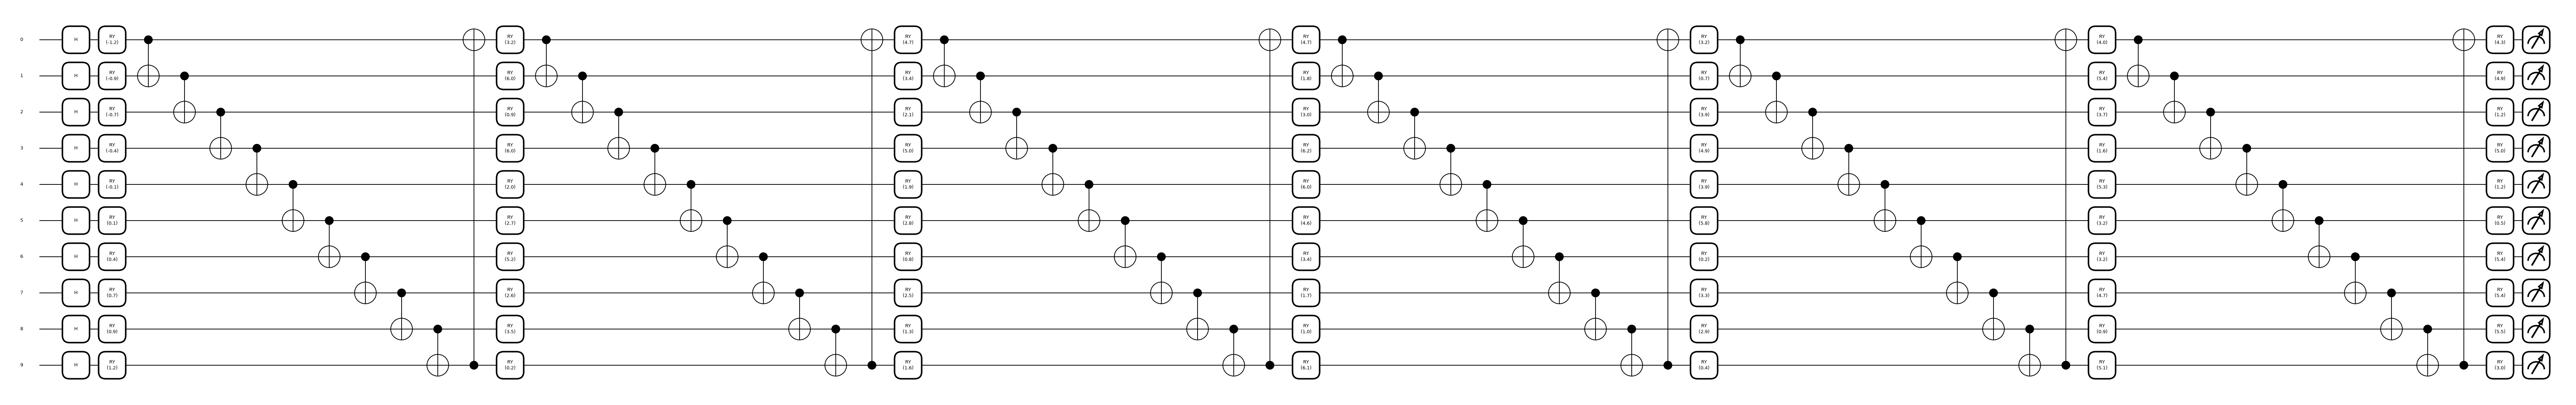

Architecture 2: the same circuit with one layer (the shallowest circuit of Table 7)


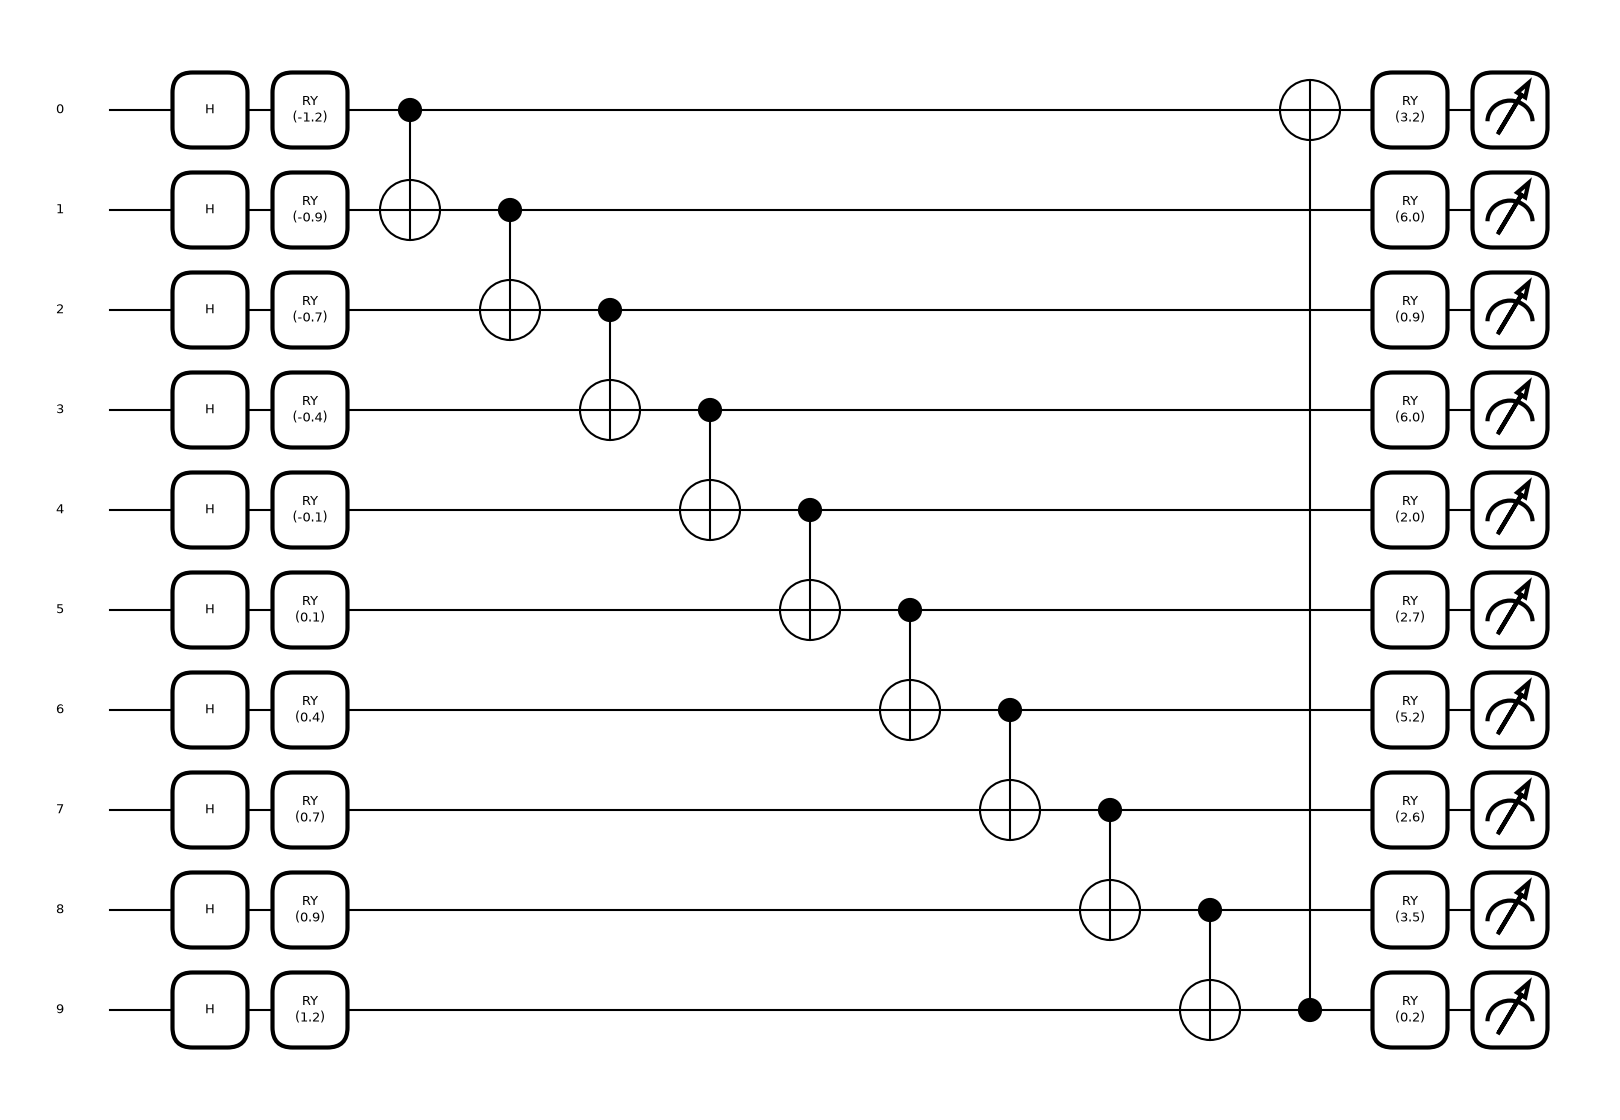

,layers,qubits,circuit depth,gates,trainable circuit parameters
0,1,10,13,40,10
1,2,10,24,60,20
2,3,10,35,80,30
3,4,10,46,100,40
4,5,10,57,120,50
5,6,10,68,140,60


Trainable parameters of the whole hybrid network are listed in section 3 (the CNN, Linear(64,10) and Linear(10,10) around the circuit).


In [8]:
# ---- 1) the torch simulator and the PennyLane QNode compute the same thing (values AND gradients), in float64
qn = make_qnode(N_QUBITS, N_LAYERS)
sim = TorchVQC(N_QUBITS, N_LAYERS).double()
r_ = np.random.default_rng(7)
x_chk = torch.tensor(r_.uniform(-np.pi / 2, np.pi / 2, (6, N_QUBITS)))
w_chk = sim.weights.detach().clone().requires_grad_(True)
ref = torch.stack([torch.stack(qn(x_chk[i], w_chk)) for i in range(len(x_chk))])
mine = sim(x_chk)
print(f"max |<Z_q> torch simulator - PennyLane QNode| over 6 inputs x 10 qubits: {(mine - ref.detach()).abs().max().item():.2e}")
g_ref, = torch.autograd.grad(ref.sum(), w_chk)
g_sim, = torch.autograd.grad(sim(x_chk).sum(), sim.weights)
print(f"max |gradient difference| w.r.t. the {sim.weights.numel()} circuit parameters: {(g_ref - g_sim).abs().max().item():.2e}")
assert (mine - ref.detach()).abs().max() < 1e-9 and (g_ref - g_sim).abs().max() < 1e-9

# ---- 2) draw the circuit that is actually executed: the PennyLane QNode (6 layers, Table 7 also uses 1 layer)
x_demo = torch.linspace(-1.2, 1.2, N_QUBITS, dtype=torch.double)
w_demo = torch.tensor(np.random.default_rng(1).uniform(0, 2 * np.pi, (N_LAYERS, N_QUBITS)))
print(f"Architecture 1: the paper's circuit, {N_QUBITS} qubits, {N_LAYERS} layers: H -> RY(x_i) data encoding -> [CNOT ring -> RY(w_li)] x {N_LAYERS} -> <Z_i>")
fig, ax = qml.draw_mpl(qn, decimals=1, level="device", fontsize=9)(x_demo, w_demo); plt.show()
qn1 = make_qnode(N_QUBITS, 1)
print("Architecture 2: the same circuit with one layer (the shallowest circuit of Table 7)")
fig, ax = qml.draw_mpl(qn1, decimals=1, level="device", fontsize=9)(x_demo, w_demo[:1]); plt.show()

# ---- 3) qubits / depth / gates / trainable parameters for every circuit depth used in Table 7
rows = []
for L in range(1, N_LAYERS + 1):
    s = qml.specs(make_qnode(N_QUBITS, L), level="device")(x_demo, w_demo[:L])
    rows.append([L, s.num_device_wires, s.resources.depth, s.resources.num_gates, L * N_QUBITS])
display(pd.DataFrame(rows, columns=["layers", "qubits", "circuit depth", "gates", "trainable circuit parameters"]))
print("Trainable parameters of the whole hybrid network are listed in section 3 (the CNN, Linear(64,10) and Linear(10,10) around the circuit).")


In [9]:
# trainable parameters of the two networks, block by block (the paper's Tables 2 and 3 list the fully connected part)
for kind in ("hybrid", "cnn"):
    net = HybridNet(kind)
    parts = {"CNN trunk": net.cnn, "Linear(64,10)": net.fc1, "quantum circuit (60 angles)" if kind == "hybrid" else "Linear(10,10) #2": net.vqc if kind == "hybrid" else net.fc2, "Linear(10,10) classifier": net.fc3}
    print(kind, {k: sum(p.numel() for p in v.parameters()) for k, v in parts.items()}, "| total", sum(p.numel() for p in net.parameters()))


hybrid {'CNN trunk': 77392, 'Linear(64,10)': 650, 'quantum circuit (60 angles)': 60, 'Linear(10,10) classifier': 110} | total 78212
cnn {'CNN trunk': 77392, 'Linear(64,10)': 650, 'Linear(10,10) #2': 110, 'Linear(10,10) classifier': 110} | total 78262


## 3. Triggers, poisoning, training and the metrics

* **Trigger functions** (all on images in [0, 1]): Badnet = a white square in the bottom-right corner; Blend = `(1-a) x + a p` with a fixed noise pattern `p`; Color = one fixed colour layer blended in;
  WaNet = a smooth fixed warping field; **Qcolor = `(R r1, G r2, B r3)`** (paper Eq. 15), a different multiplicative colour factor per channel.
* **Poisoning.** `rate` x (training-set size) non-target training images are replaced by their triggered version and relabelled to the target class (class 0).
* **Metrics** (Sec. 6.1.4). **CA**: accuracy of the clean model on clean test images. **BA**: accuracy of the backdoored model on clean test images. **ASR**: share of triggered test images (target-class images excluded, as in the paper) classified as the target class.
  **SSIM**: structural similarity between a clean and its triggered image, in percent.

In [10]:
# ---------- triggers (all act on float images in [0, 1], shape (N, 3, H, W)) ----------
def make_triggers(seed=SEED):
    g = torch.Generator().manual_seed(seed)
    blend_pattern = torch.rand(1, 3, 32, 32, generator=g)                         # CHOICE: fixed random-noise image (the paper cites Chen et al. 2017's blend)
    ins = torch.rand(1, 2, 4, 4, generator=g) * 2 - 1; ins = ins / ins.abs().mean()   # WaNet: k = 4 random control grid
    noise_grid = F.interpolate(ins, size=32, mode="bicubic", align_corners=True).permute(0, 2, 3, 1)
    ar = torch.linspace(-1, 1, 32); xx, yy = torch.meshgrid(ar, ar, indexing="ij")
    ident = torch.stack((yy, xx), 2)[None]
    wanet_grid = torch.clamp(ident + 0.5 * noise_grid / 32, -1, 1)                # s = 0.5
    return dict(blend_pattern=blend_pattern, wanet_grid=wanet_grid)
TRIG = make_triggers()

def apply_trigger(x, kind, **p):
    if kind == "badnet":                                  # white square, bottom-right corner (Gu et al. 2019)
        s = int(p["size"]); y = x.clone(); y[:, :, -s:, -s:] = 1.0; return y
    if kind == "blend":                                   # x' = (1 - a) x + a * pattern  (Chen et al. 2017)
        a = p["alpha"]; return (1 - a) * x + a * TRIG["blend_pattern"]
    if kind == "color":                                   # Color backdoor: superimpose one fixed colour layer (Jiang et al. 2023)
        a = p["alpha"]; layer = torch.tensor(p.get("rgb", (0.9, 0.3, 0.1))).view(1, 3, 1, 1)
        return (1 - a) * x + a * layer
    if kind == "wanet":                                   # WaNet warping trigger (Nguyen & Tran 2021), without the 'noise mode'
        return torch.clamp(F.grid_sample(x, TRIG["wanet_grid"].expand(len(x), -1, -1, -1), align_corners=True), 0, 1)
    if kind == "qcolor":                                  # Qcolor: I' = (R r1, G r2, B r3)   (paper Eq. 15)
        r = torch.tensor(p["ratios"], dtype=x.dtype).view(1, 3, 1, 1); return torch.clamp(x * r, 0, 1)
    raise ValueError(kind)

def _gauss_win(size=11, sigma=1.5):
    g = torch.exp(-((torch.arange(size) - size // 2) ** 2) / (2 * sigma ** 2)); g = g / g.sum()
    return (g[:, None] * g[None, :]).expand(3, 1, size, size).contiguous()
_WIN = _gauss_win()

def ssim(a, b):
    """Mean SSIM of image batches in [0, 1] (Wang et al. 2004: 11x11 Gaussian window, sigma 1.5, K1 = .01, K2 = .03), averaged over channels and images."""
    C1, C2 = 0.01 ** 2, 0.03 ** 2
    mu_a, mu_b = F.conv2d(a, _WIN, groups=3), F.conv2d(b, _WIN, groups=3)
    s_aa = F.conv2d(a * a, _WIN, groups=3) - mu_a ** 2; s_bb = F.conv2d(b * b, _WIN, groups=3) - mu_b ** 2
    s_ab = F.conv2d(a * b, _WIN, groups=3) - mu_a * mu_b
    m = ((2 * mu_a * mu_b + C1) * (2 * s_ab + C2)) / ((mu_a ** 2 + mu_b ** 2 + C1) * (s_aa + s_bb + C2))
    return float(m.mean())

def poison_train_set(ds, kind, rate, seed, **p):
    """Dirty-label poisoning (BadNets-style): a fraction `rate` of the NON-target training images is replaced by its triggered
    version and relabelled to TARGET. Returns the poisoned tensors and the poisoned indices."""
    x, y = ds["x_train"].clone(), ds["y_train"].clone()
    if rate <= 0: return x, y, np.array([], dtype=int)
    r = np.random.default_rng(seed)
    cand = np.flatnonzero(y.numpy() != TARGET)
    n_p = max(1, int(round(rate * len(y))))
    idx = r.choice(cand, n_p, replace=False)
    x[idx] = apply_trigger(x[idx], kind, **p); y[idx] = TARGET
    return x, y, idx

# ---------- training and evaluation ----------
@torch.no_grad()
def predict(model, x, bs=500):
    model.eval(); return torch.cat([model(x[i:i + bs]).argmax(1) for i in range(0, len(x), bs)])

def train_model(kind, x, y, epochs, seed, n_layers=N_LAYERS, lr=LR, verbose=False, frozen_cnn=None):
    """Train a HybridNet ('hybrid' or 'cnn') with Adam + cross-entropy. frozen_cnn: a MiniResNet whose weights are copied and frozen."""
    torch.manual_seed(seed); np.random.seed(seed)
    m = HybridNet(kind, n_layers)
    if frozen_cnn is not None:
        m.cnn.load_state_dict(frozen_cnn.state_dict())
        for p_ in m.cnn.parameters(): p_.requires_grad_(False)
    base = [p_ for n_, p_ in m.named_parameters() if p_.requires_grad and not n_.startswith("vqc.")]
    groups = [dict(params=base, lr=lr)]
    if m.vqc is not None: groups.append(dict(params=[m.vqc.weights], lr=10 * lr))      # CHOICE: the circuit angles use a 10x larger learning rate
    opt = torch.optim.Adam(groups)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs * math.ceil(len(x) / BATCH))
    g = torch.Generator().manual_seed(seed); t0 = time.time(); hist = []
    for ep in range(epochs):
        m.train()
        if frozen_cnn is not None: m.cnn.eval()                 # frozen BN statistics as well
        perm = torch.randperm(len(x), generator=g); tot = 0.0
        for i in range(0, len(x), BATCH):
            ib = perm[i:i + BATCH]
            loss = F.cross_entropy(m(x[ib]), y[ib])
            opt.zero_grad(); loss.backward(); opt.step(); sched.step(); tot += float(loss) * len(ib)
        hist.append(tot / len(x))
        if verbose: print(f"    epoch {ep+1}/{epochs} loss {hist[-1]:.3f} ({time.time()-t0:.0f} s)")
    m.eval(); m.train_time = time.time() - t0; m.hist = hist
    return m

def evaluate(model, ds, kind=None, **p):
    """CA/BA = accuracy on clean test images; ASR = share of triggered NON-target test images classified as TARGET (paper Sec. 6.1.1/6.1.4)."""
    xt, yt = ds["x_test"], ds["y_test"]
    acc = float((predict(model, xt) == yt).float().mean()) * 100
    if kind is None: return dict(acc=acc, asr=float("nan"), ssim=float("nan"))
    keep = yt != TARGET
    xtrig = apply_trigger(xt[keep], kind, **p)
    asr = float((predict(model, xtrig) == TARGET).float().mean()) * 100
    return dict(acc=acc, asr=asr, ssim=100 * ssim(xt[keep], xtrig))


The next figure shows what the five triggers do to real test images and the SSIM of each on the whole test set (compare the paper's Figures 2 and 8). The Qcolor shift here is a hand-picked example; the real ratios come from NSGA-II in section 7.

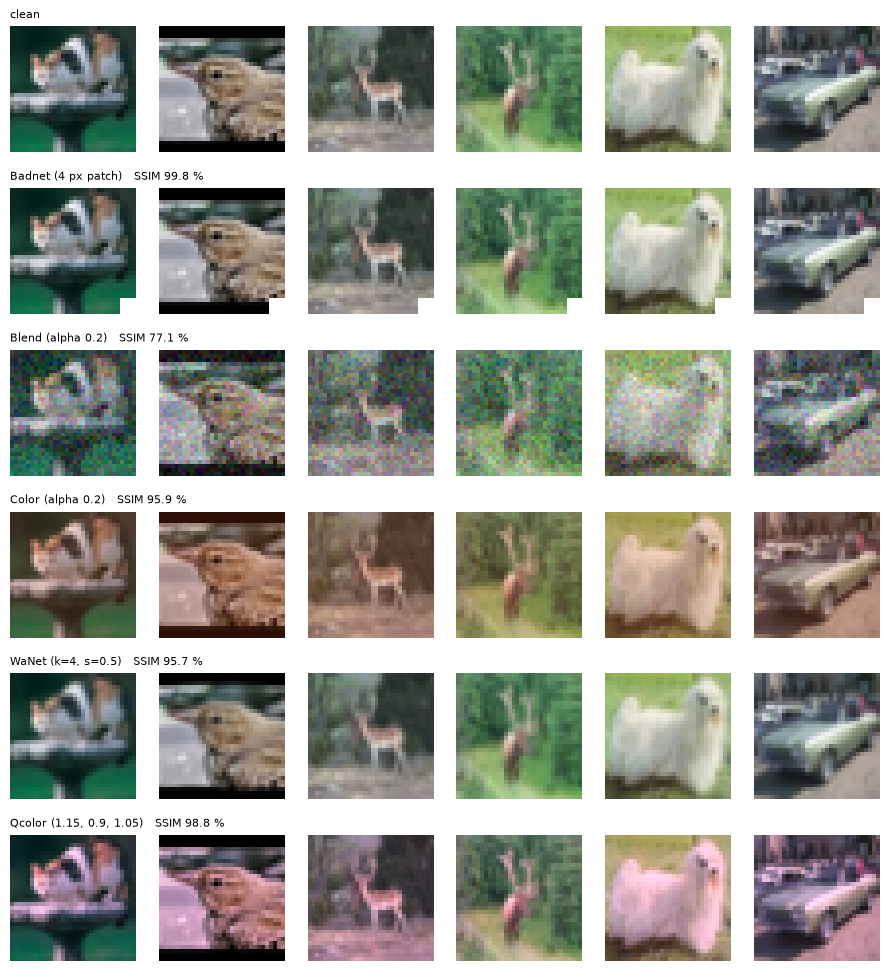

In [11]:
# ---- Clean vs triggered images (the paper's Fig. 2 and Fig. 8) with the SSIM of every trigger on the whole test set
TRIGGERS_DEMO = {"Badnet (4 px patch)": ("badnet", dict(size=4)), "Blend (alpha 0.2)": ("blend", dict(alpha=0.2)),
                 "Color (alpha 0.2)": ("color", dict(alpha=0.2)), "WaNet (k=4, s=0.5)": ("wanet", {}),
                 "Qcolor (1.15, 0.9, 1.05)": ("qcolor", dict(ratios=(1.15, 0.9, 1.05)))}
d = DATA["cifar10"]; xs = d["x_test"][d["y_test"] != TARGET]
fig, axs = plt.subplots(len(TRIGGERS_DEMO) + 1, 6, figsize=(9, 1.65 * (len(TRIGGERS_DEMO) + 1)))
for k in range(6):
    axs[0, k].imshow(xs[k].permute(1, 2, 0)); axs[0, k].axis("off")
axs[0, 0].set_title("clean", fontsize=8, loc="left")
for r, (nm, (kind, p)) in enumerate(TRIGGERS_DEMO.items(), start=1):
    xt = apply_trigger(xs[:6], kind, **p)
    for k in range(6): axs[r, k].imshow(xt[k].permute(1, 2, 0)); axs[r, k].axis("off")
    axs[r, 0].set_title(f"{nm}   SSIM {100 * ssim(xs, apply_trigger(xs, kind, **p)):.1f} %", fontsize=8, loc="left")
plt.tight_layout(); plt.show()


## 4. Clean models and a classical baseline on identical inputs

Two clean victims are trained on CIFAR-10: the **HQNN** (CNN + 10-qubit circuit) and the **classical CNN** (same trunk, three ordinary fully connected layers). As an extra check of what the circuit contributes, a RandomForest and an RBF-SVC
are fitted (training split only) on exactly the **ten angles that enter the circuit**. The runner caches every trained model so a number needed twice is trained once.

In [12]:
# ---------- experiment runner: every run is cached, so a number that is needed twice is trained once ----------
RUNS, CLEAN = {}, {}

def clean_model(arch, dsname, seed=SEED, n_layers=N_LAYERS):
    key = (arch, dsname, seed, n_layers)
    if key not in CLEAN:
        ds = DATA[dsname]
        CLEAN[key] = train_model(arch, ds["x_train"], ds["y_train"], EPOCHS, seed, n_layers)
    return CLEAN[key]

def attack(arch, dsname, kind, rate, seed=SEED, n_layers=N_LAYERS, **p):
    """Train a backdoored model (poisoning rate `rate`) and return its metrics: BA (clean test accuracy), ASR, SSIM, plus the model."""
    key = (arch, dsname, kind, round(rate, 4), seed, n_layers, repr(sorted(p.items())))
    if key not in RUNS:
        ds = DATA[dsname]
        x, y, idx = poison_train_set(ds, kind, rate, seed, **p)
        m = train_model(arch, x, y, EPOCHS, seed, n_layers)
        ev = evaluate(m, ds, kind, **p)
        RUNS[key] = dict(model=m, n_poison=len(idx), time=m.train_time, **ev)
        print(f"  [{arch:6s} {dsname:7s} {kind:7s} rate {rate:5.2%} {p}] BA {ev['acc']:.2f}  ASR {ev['asr']:.2f}  SSIM {ev['ssim']:.1f}  ({m.train_time:.0f} s)", flush=True)
    return RUNS[key]


In [13]:
# ---------- clean models (no poisoning): the reference accuracy CA of the paper ----------
t0 = time.time()
cnn_clean = clean_model("cnn", "cifar10"); hyb_clean = clean_model("hybrid", "cifar10")
ds = DATA["cifar10"]
ca = {a: 100 * float((predict(m, ds["x_test"]) == ds["y_test"]).float().mean()) for a, m in (("cnn", cnn_clean), ("hybrid", hyb_clean))}
print(f"clean CIFAR-10 test accuracy: classical CNN {ca['cnn']:.2f} %, hybrid HQNN {ca['hybrid']:.2f} %   (training {cnn_clean.train_time:.0f} s / {hyb_clean.train_time:.0f} s)")

# ---------- classical baselines on the SAME input as the quantum circuit: the 10 angles that the CNN hands to the circuit ----------
@torch.no_grad()
def angles_of(model, x, bs=500):
    model.eval(); return torch.cat([model.angles(x[i:i + bs]) for i in range(0, len(x), bs)]).numpy()
A_tr, A_te = angles_of(hyb_clean, ds["x_train"]), angles_of(hyb_clean, ds["x_test"])
rows = [["HQNN (CNN + 10-qubit VQC + Linear)", "images", ca["hybrid"]], ["classical CNN (same CNN + 3 Linear layers)", "images", ca["cnn"]]]
for nm, clf in (("RandomForest", RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1)), ("SVC (rbf, C=1)", SVC(kernel="rbf", C=1.0, random_state=SEED))):
    t1 = time.time(); clf.fit(A_tr, ds["y_train"].numpy()); acc = 100 * accuracy_score(ds["y_test"].numpy(), clf.predict(A_te))
    rows.append([nm + " replacing the VQC", "the 10 circuit input angles of the HQNN", acc])
display(pd.DataFrame(rows, columns=["model", "input", "clean test accuracy (%)"]).round(2))
print("The three classical heads see exactly the 10 numbers that the circuit sees; they show how much the circuit itself contributes to the clean accuracy.")
print(f"({time.time() - t0:.0f} s)")


clean CIFAR-10 test accuracy: classical CNN 35.40 %, hybrid HQNN 27.00 %   (training 30 s / 37 s)


,model,input,clean test accuracy (%)
0,HQNN (CNN + 10-qubit VQC + Linear),images,27.0
1,classical CNN (same CNN + 3 Linear layers),images,35.4
2,RandomForest replacing the VQC,the 10 circuit input angles of the HQNN,37.3
3,"SVC (rbf, C=1) replacing the VQC",the 10 circuit input angles of the HQNN,37.7


The three classical heads see exactly the 10 numbers that the circuit sees; they show how much the circuit itself contributes to the clean accuracy.
(83 s)


## 5. HQNN versus CNN under Badnet and Blend (Table 1)

Same poisoning rate (0.1), same data, same trunk; only the head differs. The paper's claim: the HQNN is the harder victim, the weak triggers (patch 1 and 4, blend 0.05 and 0.1) do not work at all against it,
only larger ones do. Our patch sizes are 1 to 4 pixels because the images are 32 x 32 instead of 224 x 224. After the table, the cell picks, as the paper does, the **smallest trigger strength that attacks the HQNN successfully** for the later experiments.

  [cnn    cifar10 badnet  rate 10.00% {'size': 1}] BA 22.70  ASR 63.36  SSIM 100.0  (30 s)


  [cnn    cifar10 badnet  rate 10.00% {'size': 4}] BA 22.30  ASR 66.82  SSIM 99.8  (27 s)


  [cnn    cifar10 blend   rate 10.00% {'alpha': 0.05}] BA 23.80  ASR 61.92  SSIM 97.8  (30 s)


  [cnn    cifar10 blend   rate 10.00% {'alpha': 0.2}] BA 23.90  ASR 100.00  SSIM 77.1  (29 s)


  [hybrid cifar10 badnet  rate 10.00% {'size': 1}] BA 22.30  ASR 27.84  SSIM 100.0  (42 s)


  [hybrid cifar10 badnet  rate 10.00% {'size': 4}] BA 19.80  ASR 92.54  SSIM 99.8  (40 s)


  [hybrid cifar10 blend   rate 10.00% {'alpha': 0.05}] BA 20.70  ASR 42.54  SSIM 97.8  (44 s)


  [hybrid cifar10 blend   rate 10.00% {'alpha': 0.2}] BA 24.60  ASR 99.89  SSIM 77.1  (38 s)


,CA,patch 1 BA,patch 1 ASR,patch 4 BA,patch 4 ASR,blend 0.05 BA,blend 0.05 ASR,blend 0.2 BA,blend 0.2 ASR
model,,,,,,,,,
CNN,35.4,22.7,63.36,22.3,66.82,23.8,61.92,23.9,100.00
HQNN,27.0,22.3,27.84,19.8,92.54,20.7,42.54,24.6,99.89


Table 1 analogue (CIFAR-10, poisoning rate 0.1, target class 0); 299 s
smallest successful settings for the HQNN (ASR >= 80 %): Badnet patch 4 px, Blend ratio 0.2  (largest tried if none succeeded)


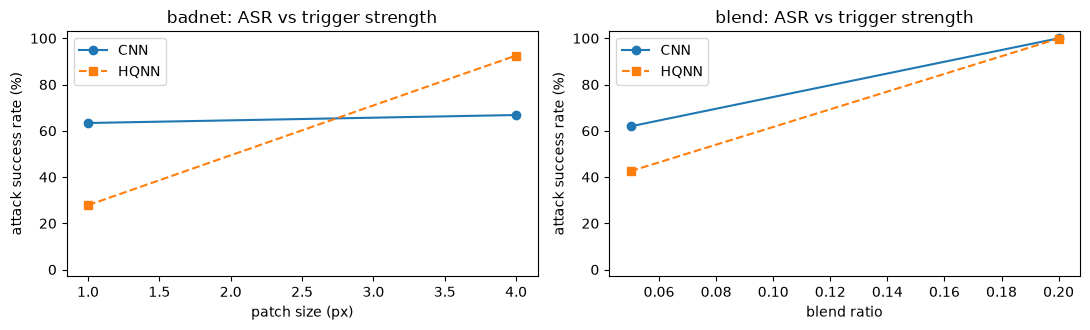

In [14]:
# ---------- Table 1: HQNN vs CNN against Badnet (patch size) and Blend (ratio), poisoning rate 0.1 ----------
t0 = time.time()
settings = [("badnet", dict(size=s)) for s in PATCH_SIZES] + [("blend", dict(alpha=a)) for a in BLEND_RATIOS]
t1_rows = []
for arch, label in (("cnn", "CNN"), ("hybrid", "HQNN")):
    row = {"model": label, "CA": 100 * float((predict(CLEAN[(arch, "cifar10", SEED, N_LAYERS)], DATA["cifar10"]["x_test"]) == DATA["cifar10"]["y_test"]).float().mean())}
    for kind, p in settings:
        r_ = attack(arch, "cifar10", kind, POISON_MAIN, **p)
        tag = f"patch {p['size']}" if kind == "badnet" else f"blend {p['alpha']}"
        row[tag + " BA"], row[tag + " ASR"] = r_["acc"], r_["asr"]
    t1_rows.append(row)
tab1 = pd.DataFrame(t1_rows).set_index("model")
display(tab1.round(2))
print(f"Table 1 analogue (CIFAR-10, poisoning rate {POISON_MAIN}, target class {TARGET}); {time.time() - t0:.0f} s")

# choose the trigger strengths for the later experiments the way the paper does: the smallest setting that attacks the HQNN successfully
def smallest_success(kind, key, values, thr=80.0):
    for v in values:
        if RUNS[("hybrid", "cifar10", kind, round(POISON_MAIN, 4), SEED, N_LAYERS, repr(sorted({key: v}.items())))]["asr"] >= thr: return v
    return values[-1]
BADNET_SIZE = smallest_success("badnet", "size", PATCH_SIZES); BLEND_ALPHA = smallest_success("blend", "alpha", BLEND_RATIOS)
print(f"smallest successful settings for the HQNN (ASR >= 80 %): Badnet patch {BADNET_SIZE} px, Blend ratio {BLEND_ALPHA}  (largest tried if none succeeded)")

fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, (kind, key, vals, xl) in zip(axs, (("badnet", "size", PATCH_SIZES, "patch size (px)"), ("blend", "alpha", BLEND_RATIOS, "blend ratio"))):
    for arch, label, mk in (("cnn", "CNN", "o-"), ("hybrid", "HQNN", "s--")):
        ax.plot(vals, [RUNS[(arch, "cifar10", kind, round(POISON_MAIN, 4), SEED, N_LAYERS, repr(sorted({key: v}.items())))]["asr"] for v in vals], mk, label=label)
    ax.set_xlabel(xl); ax.set_ylabel("attack success rate (%)"); ax.set_ylim(-3, 103); ax.legend(); ax.set_title(f"{kind}: ASR vs trigger strength")
plt.tight_layout(); plt.show()


## 6. Is the HQNN's robustness explained by parameters or gradients? (Tables 2 and 3)

The paper rules out two simple explanations for the HQNN's robustness: the circuit does not have more parameters than the layer it replaces (60 against 100), and its gradients are not smaller. We count parameters and measure
gradient norms of the clean-trained models, layer by layer and in total.

In [15]:
# ---------- Tables 2 and 3: parameters and gradient norms of the fully connected part of the HQNN and of the CNN ----------
def grad_report(model, x, y):
    model.eval(); model.zero_grad()
    F.cross_entropy(model(x), y).backward()
    def norm(ps): return float(torch.sqrt(sum((p.grad ** 2).sum() for p in ps if p.grad is not None)))
    n = lambda ps: sum(p.numel() for p in ps)
    if model.kind == "hybrid":
        layers = [("FC layer 1: Linear(64, 10)", list(model.fc1.parameters())), ("layer 2: VQC (10 qubits, 6 layers)", list(model.vqc.parameters())),
                  ("FC layer 3: Linear(10, 10)", list(model.fc3.parameters()))]
    else:
        layers = [("FC layer 1: Linear(64, 10)", list(model.fc1.parameters())), ("FC layer 2: Linear(10, 10)", list(model.fc2.parameters())),
                  ("FC layer 3: Linear(10, 10)", list(model.fc3.parameters()))]
    allp = [p for p in model.parameters()]; gall = torch.cat([p.grad.flatten() for p in allp if p.grad is not None])
    return [(nm, n(ps), norm(ps)) for nm, ps in layers], dict(total=n(allp), norm=float(gall.norm()), avg=float(gall.mean()), mx=float(gall.max()), mn=float(gall.min()))

xb, yb = DATA["cifar10"]["x_test"][:256], DATA["cifar10"]["y_test"][:256]
gh, th = grad_report(hyb_clean, xb, yb); gc, tc = grad_report(cnn_clean, xb, yb)
display(pd.DataFrame({"HQNN: layer": [r[0] for r in gh], "HQNN params": [r[1] for r in gh], "HQNN grad norm": [r[2] for r in gh],
                      "CNN: layer": [r[0] for r in gc], "CNN params": [r[1] for r in gc], "CNN grad norm": [r[2] for r in gc]}).round(4))
display(pd.DataFrame({"HQNN": th, "CNN": tc}).T.rename(columns={"total": "total params", "norm": "total grad norm", "avg": "avg grad", "mx": "max grad", "mn": "min grad"}))
print("Gradients of the clean-trained models on 256 clean test images (the paper does not say where it measured them).")


,HQNN: layer,HQNN params,HQNN grad norm,CNN: layer,CNN params,CNN grad norm
0,"FC layer 1: Linear(64, 10)",650,0.1028,"FC layer 1: Linear(64, 10)",650,0.2365
1,"layer 2: VQC (10 qubits, 6 layers)",60,0.0419,"FC layer 2: Linear(10, 10)",110,0.3153
2,"FC layer 3: Linear(10, 10)",110,0.1525,"FC layer 3: Linear(10, 10)",110,0.4029


,total params,total grad norm,avg grad,max grad,min grad
HQNN,78212.0,1.941304,-0.000416,0.173690,-0.222460
CNN,78262.0,4.900678,-0.001647,0.486491,-0.764965


Gradients of the clean-trained models on 256 clean test images (the paper does not say where it measured them).


## 7. The Qcolor backdoor and NSGA-II (Section 5)

**Idea.** Because the circuit's input angles are computed from image colours, a *global, subtle colour shift* `I' = (R r1, G r2, B r3)` moves every image's angles slightly in the same direction, which the CNN can learn to detect.
Humans notice absolute colour much less than local patterns, so SSIM stays high.

**Choosing r1, r2, r3.** Two goals conflict: a big shift is easy to learn but visible. NSGA-II (Deb et al. 2002) searches the Pareto front: it keeps a population of candidate ratios, creates children by tournament selection,
crossover and mutation, merges parents and children, sorts them into non-dominated fronts and truncates by crowding distance (Algorithm 1 in the paper). The cell below implements this in about 40 lines, then runs it. Every candidate is evaluated by
poisoning a small training set, training an HQNN for a few epochs and measuring BA, ASR and SSIM on the **validation** split; the two objectives are `f1 = (1-BA) + (1-ASR)` (the classification and attack terms of Eq. 18) and `f2 = 1 - SSIM`.
From the final Pareto front we take the stealthiest candidate that still reaches a validation ASR of 90 %.

In [16]:
# ---------- NSGA-II (Deb et al. 2002), written out so that Algorithm 1 of the paper can be followed line by line ----------
def non_dominated_sort(Fv):
    """Return the list of Pareto fronts (lists of indices) of the objective matrix Fv (all objectives are minimised)."""
    n = len(Fv); dom_by = [[] for _ in range(n)]; cnt = np.zeros(n, int); fronts = [[]]
    for i in range(n):
        for j in range(n):
            if i == j: continue
            if np.all(Fv[i] <= Fv[j]) and np.any(Fv[i] < Fv[j]): dom_by[i].append(j)       # i dominates j
            elif np.all(Fv[j] <= Fv[i]) and np.any(Fv[j] < Fv[i]): cnt[i] += 1
        if cnt[i] == 0: fronts[0].append(i)
    k = 0
    while fronts[k]:
        nxt = []
        for i in fronts[k]:
            for j in dom_by[i]:
                cnt[j] -= 1
                if cnt[j] == 0: nxt.append(j)
        k += 1; fronts.append(nxt)
    return fronts[:-1]

def crowding_distance(Fv, front):
    d = np.zeros(len(front)); sub = Fv[front]
    for m in range(Fv.shape[1]):
        o = np.argsort(sub[:, m]); d[o[0]] = d[o[-1]] = np.inf
        span = sub[o[-1], m] - sub[o[0], m]
        if span > 0:
            for k in range(1, len(front) - 1): d[o[k]] += (sub[o[k + 1], m] - sub[o[k - 1], m]) / span
    return d

def nsga2(fitness, lo, hi, pop_size, generations, seed, log=print):
    """Minimise fitness(r) -> (f1, f2) over r in [lo, hi]^3. Algorithm 1 of the paper: tournament selection, SBX crossover,
    polynomial mutation, merge parents + children, non-dominated sorting, crowding-distance truncation."""
    r = np.random.default_rng(seed)
    P = r.uniform(lo, hi, (pop_size, 3)); FP = np.array([fitness(p) for p in P]); log(f"  generation 0: best f1 {FP[:,0].min():.3f}, best f2 {FP[:,1].min():.4f}")
    def rank_crowd(Fv):
        rank = np.zeros(len(Fv), int); crowd = np.zeros(len(Fv))
        for k, fr in enumerate(non_dominated_sort(Fv)):
            rank[fr] = k; crowd[fr] = crowding_distance(Fv, fr)
        return rank, crowd
    for g in range(1, generations + 1):
        rank, crowd = rank_crowd(FP); Q = []
        def pick():
            a, b = r.integers(0, len(P), 2)
            return a if (rank[a], -crowd[a]) < (rank[b], -crowd[b]) else b
        while len(Q) < pop_size:
            p1, p2 = P[pick()], P[pick()]; eta = 15
            u = r.random(3); beta = np.where(u <= .5, (2 * u) ** (1 / (eta + 1)), (1 / (2 * (1 - u))) ** (1 / (eta + 1)))
            c1 = .5 * ((1 + beta) * p1 + (1 - beta) * p2); c2 = .5 * ((1 - beta) * p1 + (1 + beta) * p2)
            for c in (c1, c2):
                mut = r.random(3) < 1 / 3; c[mut] += r.normal(0, 0.05, mut.sum()) * (hi - lo)       # Gaussian mutation (CHOICE)
                Q.append(np.clip(c, lo, hi))
        Q = np.array(Q[:pop_size]); FQ = np.array([fitness(q) for q in Q])
        R = np.vstack([P, Q]); FR = np.vstack([FP, FQ]); newP, newF = [], []
        for fr in non_dominated_sort(FR):
            if len(newP) + len(fr) <= pop_size:
                newP += list(R[fr]); newF += list(FR[fr])
            else:
                cd = crowding_distance(FR, fr); keep = np.array(fr)[np.argsort(-cd)][:pop_size - len(newP)]
                newP += list(R[keep]); newF += list(FR[keep]); break
        P, FP = np.array(newP), np.array(newF)
        log(f"  generation {g}: best f1 {FP[:,0].min():.3f}, best f2 {FP[:,1].min():.4f}, Pareto front size {len(non_dominated_sort(FP)[0])}")
    return P, FP


NSGA-II: population 6, generations 2; every candidate = one hybrid model trained for 2 epochs on 1500 images


  generation 0: best f1 0.825, best f2 0.0345


  generation 1: best f1 0.825, best f2 0.0287, Pareto front size 5


  generation 2: best f1 0.825, best f2 0.0287, Pareto front size 6


,r1,r2,r3,BA,ASR,SSIM,f1,f2
10,1.1684,1.2538,0.9289,20.6,35.3795,97.1265,1.4402,0.0287
15,1.1386,1.3014,0.9168,20.5,63.3929,96.7434,1.1611,0.0326
2,1.2611,1.2861,0.6281,19.2,73.2143,89.9253,1.0759,0.1007
2,1.2611,1.2861,0.6281,19.2,73.2143,89.9253,1.0759,0.1007
11,0.7343,1.0507,0.5784,19.0,96.6518,89.2774,0.8435,0.1072
5,0.7272,1.0546,0.5638,20.1,97.4330,88.4950,0.8247,0.1150


chosen Qcolor ratios (r1, r2, r3) = (0.734, 1.051, 0.578)  (validation ASR 96.7 %, SSIM 89.28 %)  [246 s]


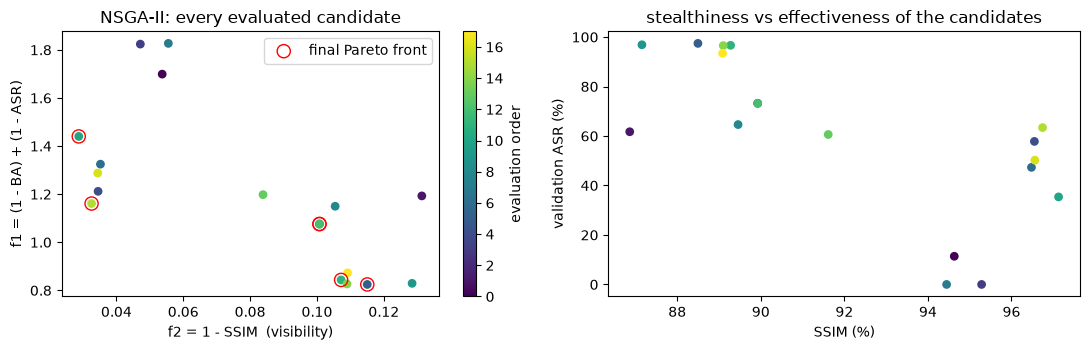

In [17]:
# ---------- Qcolor: choose the channel ratios (r1, r2, r3) with NSGA-II (paper Sec. 5.2, Algorithm 1) ----------
dsc = DATA["cifar10"]
ds_nsga = dict(x_train=dsc["x_train"][:NSGA_TRAIN], y_train=dsc["y_train"][:NSGA_TRAIN], x_test=dsc["x_val"], y_test=dsc["y_val"])   # candidates are scored on the VALIDATION split
nsga_log = []

def qcolor_fitness(r):
    """Two objectives (both minimised), the two groups of Eq. 18: f1 = (1 - BA) + (1 - ASR)  [clean loss + attack loss], f2 = 1 - SSIM  [stealthiness]."""
    ratios = tuple(float(v) for v in r)
    x, y, _ = poison_train_set(ds_nsga, "qcolor", POISON_MAIN, SEED, ratios=ratios)
    m = train_model("hybrid", x, y, NSGA_EPOCHS, SEED)
    ev = evaluate(m, ds_nsga, "qcolor", ratios=ratios)
    f = (2 - ev["acc"] / 100 - ev["asr"] / 100, 1 - ev["ssim"] / 100)
    nsga_log.append(dict(r1=ratios[0], r2=ratios[1], r3=ratios[2], BA=ev["acc"], ASR=ev["asr"], SSIM=ev["ssim"], f1=f[0], f2=f[1]))
    return f

t0 = time.time()
print(f"NSGA-II: population {NSGA_POP}, generations {NSGA_GEN}; every candidate = one hybrid model trained for {NSGA_EPOCHS} epochs on {NSGA_TRAIN} images")
P_fin, F_fin = nsga2(qcolor_fitness, 0.5, 1.5, NSGA_POP, NSGA_GEN, SEED)
log_df = pd.DataFrame(nsga_log)
front = non_dominated_sort(F_fin)[0]
fin = log_df.iloc[[int(np.argmin(np.abs(log_df[["f1", "f2"]].values - F_fin[i]).sum(1))) for i in front]].sort_values("f2")
display(fin.round(4))

# the final choice: among the Pareto-optimal ratios, the stealthiest one (highest SSIM) that still attacks (validation ASR >= 90 %); otherwise the most effective one
ok = fin[fin["ASR"] >= 90]
best = ok.sort_values("SSIM", ascending=False).iloc[0] if len(ok) else fin.sort_values("f1").iloc[0]
QRATIOS = (float(best.r1), float(best.r2), float(best.r3))
print(f"chosen Qcolor ratios (r1, r2, r3) = {tuple(round(v, 3) for v in QRATIOS)}  (validation ASR {best.ASR:.1f} %, SSIM {best.SSIM:.2f} %)  [{time.time() - t0:.0f} s]")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
sc = ax[0].scatter(log_df["f2"], log_df["f1"], c=np.arange(len(log_df)), cmap="viridis", s=28)
ax[0].scatter(fin["f2"], fin["f1"], facecolors="none", edgecolors="r", s=90, label="final Pareto front"); plt.colorbar(sc, ax=ax[0], label="evaluation order")
ax[0].set_xlabel("f2 = 1 - SSIM  (visibility)"); ax[0].set_ylabel("f1 = (1 - BA) + (1 - ASR)"); ax[0].set_title("NSGA-II: every evaluated candidate"); ax[0].legend()
ax[1].scatter(log_df["SSIM"], log_df["ASR"], c=np.arange(len(log_df)), cmap="viridis", s=28); ax[1].set_xlabel("SSIM (%)"); ax[1].set_ylabel("validation ASR (%)")
ax[1].set_title("stealthiness vs effectiveness of the candidates")
plt.tight_layout(); plt.show()


## 8. Qcolor on CIFAR-10 and MNIST (Table 5)

Poisoning rate 0.1. For each dataset a clean HQNN and a Qcolor-backdoored HQNN are trained; we report the clean accuracy CA, the ASR of the *clean* model (it must not react to the trigger), BA and ASR of the backdoored model, and SSIM. The headline rows average the seeds in `SEEDS_HEADLINE`. As an extra, the same attack is run against the classical CNN.

In [18]:
# ---------- Table 5: Qcolor on CIFAR-10 and MNIST (HQNN), poisoning rate 0.1; mean +- std over the seeds in SEEDS_HEADLINE ----------
t0 = time.time(); t5 = []; t5d = {}
for dsname in ("cifar10", "mnist"):
    cas, bas, asrs, ca_asr, ssims = [], [], [], [], []
    for sd in SEEDS_HEADLINE:
        cm = clean_model("hybrid", dsname, sd)
        cas.append(100 * float((predict(cm, DATA[dsname]["x_test"]) == DATA[dsname]["y_test"]).float().mean()))
        ca_asr.append(evaluate(cm, DATA[dsname], "qcolor", ratios=QRATIOS)["asr"])                      # the clean model must NOT react to the trigger
        r_ = attack("hybrid", dsname, "qcolor", POISON_MAIN, seed=sd, ratios=QRATIOS); bas.append(r_["acc"]); asrs.append(r_["asr"]); ssims.append(r_["ssim"])
    fmt = lambda v: f"{np.mean(v):.2f}" + (f" +- {np.std(v):.2f}" if len(v) > 1 else "")
    t5d[dsname] = dict(ca=np.mean(cas), clean_asr=np.mean(ca_asr), ba=np.mean(bas), asr=np.mean(asrs), ssim=np.mean(ssims))
    t5.append([dsname, "HQNN (small ResNet + 10q VQC)", fmt(cas), fmt(ca_asr), fmt(bas), fmt(asrs), fmt(ssims)])
# the same attack on the purely classical CNN (CIFAR-10): the paper claims the HQNN is the harder victim
r_cnn = attack("cnn", "cifar10", "qcolor", POISON_MAIN, ratios=QRATIOS)
t5.append(["cifar10", "classical CNN (for comparison)", f"{ca['cnn']:.2f}", "-", f"{r_cnn['acc']:.2f}", f"{r_cnn['asr']:.2f}", f"{r_cnn['ssim']:.2f}"])
tab5 = pd.DataFrame(t5, columns=["dataset", "model", "clean model CA (%)", "clean model ASR (%)", "backdoor model BA (%)", "backdoor model ASR (%)", "SSIM (%)"])
display(tab5)
print(f"Table 5 analogue; {time.time() - t0:.0f} s")


  [hybrid cifar10 qcolor  rate 10.00% {'ratios': (0.7342842136860895, 1.05072453292121, 0.5783519951502119)}] BA 22.90  ASR 98.55  SSIM 89.3  (50 s)


  [hybrid mnist   qcolor  rate 10.00% {'ratios': (0.7342842136860895, 1.05072453292121, 0.5783519951502119)}] BA 69.70  ASR 100.00  SSIM 91.0  (49 s)


  [cnn    cifar10 qcolor  rate 10.00% {'ratios': (0.7342842136860895, 1.05072453292121, 0.5783519951502119)}] BA 25.60  ASR 99.33  SSIM 89.3  (33 s)


,dataset,model,clean model CA (%),clean model ASR (%),backdoor model BA (%),backdoor model ASR (%),SSIM (%)
0,cifar10,HQNN (small ResNet + 10q VQC),27.00,1.22,22.90,98.55,89.27
1,mnist,HQNN (small ResNet + 10q VQC),67.70,0.33,69.70,100.00,90.99
2,cifar10,classical CNN (for comparison),35.40,-,25.60,99.33,89.27


Table 5 analogue; 196 s


## 9. Can the backdoor be placed in the quantum head alone? (Table 4)

The paper freezes a *clean* CNN and trains only the quantum head (Linear, circuit, Linear) on the poisoned data. Its result: ASR 0.00, so the HQNN backdoor needs the CNN to learn the trigger. The same experiment with Badnet and Qcolor, next to the normal end-to-end poisoning.

In [19]:
# ---------- Table 4: backdoor injected by training ONLY the quantum head on top of a frozen CLEAN CNN ----------
t0 = time.time(); ds = DATA["cifar10"]; t4 = []; t4d = {}
for kind, p in (("badnet", dict(size=BADNET_SIZE)), ("qcolor", dict(ratios=QRATIOS))):
    x, y, idx = poison_train_set(ds, kind, POISON_MAIN, SEED, **p)
    frozen = train_model("hybrid", x, y, EPOCHS, SEED, frozen_cnn=hyb_clean.cnn)
    ev = evaluate(frozen, ds, kind, **p)
    free = attack("hybrid", "cifar10", kind, POISON_MAIN, **p)
    t4d[kind] = dict(frozen_ba=ev['acc'], frozen_asr=ev['asr'], free_ba=free['acc'], free_asr=free['asr'])
    t4.append([kind, f"{ca['hybrid']:.2f}", f"{evaluate(hyb_clean, ds, kind, **p)['asr']:.2f}", f"{ev['acc']:.2f}", f"{ev['asr']:.2f}", f"{free['acc']:.2f}", f"{free['asr']:.2f}"])
display(pd.DataFrame(t4, columns=["trigger", "clean model CA", "clean model ASR", "frozen-CNN backdoor BA", "frozen-CNN backdoor ASR",
                                   "end-to-end backdoor BA", "end-to-end backdoor ASR"]))
print(f"Table 4 analogue; {time.time() - t0:.0f} s")


,trigger,clean model CA,clean model ASR,frozen-CNN backdoor BA,frozen-CNN backdoor ASR,end-to-end backdoor BA,end-to-end backdoor ASR
0,badnet,27.00,5.79,23.60,25.61,19.80,92.54
1,qcolor,27.00,1.22,23.20,67.37,22.90,98.55


Table 4 analogue; 67 s


## 10. Low poisoning rates (Table 6)

Five triggers against the HQNN at decreasing poisoning rates. The paper's claim: Qcolor still works at 1 %, every other trigger fails at 4 % or below. Blend and Badnet use the strengths selected in section 5.

  [hybrid cifar10 blend   rate 2.00% {'alpha': 0.2}] BA 27.70  ASR 13.59  SSIM 77.1  (49 s)


  [hybrid cifar10 badnet  rate 2.00% {'size': 4}] BA 29.20  ASR 8.69  SSIM 99.8  (46 s)


  [hybrid cifar10 wanet   rate 10.00% {}] BA 21.60  ASR 51.67  SSIM 95.7  (40 s)


  [hybrid cifar10 wanet   rate 2.00% {}] BA 28.70  ASR 8.24  SSIM 95.7  (44 s)


  [hybrid cifar10 color   rate 10.00% {'alpha': 0.2}] BA 21.60  ASR 93.32  SSIM 95.9  (45 s)


  [hybrid cifar10 color   rate 2.00% {'alpha': 0.2}] BA 28.10  ASR 7.91  SSIM 95.9  (44 s)


  [hybrid cifar10 qcolor  rate 2.00% {'ratios': (0.7342842136860895, 1.05072453292121, 0.5783519951502119)}] BA 26.10  ASR 72.16  SSIM 89.3  (42 s)


,10% BA,10% ASR,2% BA,2% ASR
trigger,,,,
Blend,24.6,99.89,27.7,13.59
Badnet,19.8,92.54,29.2,8.69
WaNet,21.6,51.67,28.7,8.24
Color,21.6,93.32,28.1,7.91
Qcolor,22.9,98.55,26.1,72.16


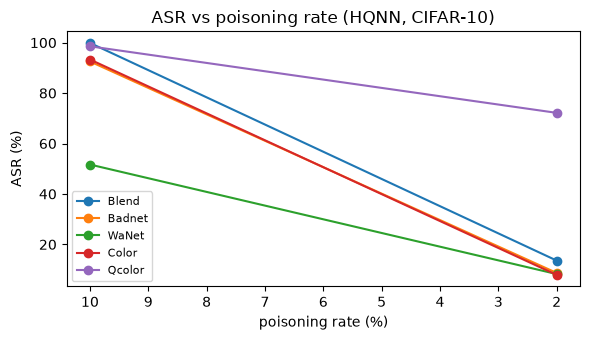

Table 6 analogue; 330 s


In [20]:
# ---------- Table 6: different triggers at different poisoning rates (HQNN, CIFAR-10) ----------
t0 = time.time()
TRIGS6 = [("Blend", "blend", dict(alpha=BLEND_ALPHA)), ("Badnet", "badnet", dict(size=BADNET_SIZE)), ("WaNet", "wanet", {}),
          ("Color", "color", dict(alpha=0.2)), ("Qcolor", "qcolor", dict(ratios=QRATIOS))]
rows6 = []
for nm, kind, p in TRIGS6:
    row = {"trigger": nm}
    for rate in POISON_RATES:
        r_ = attack("hybrid", "cifar10", kind, rate, **p)
        row[f"{rate:.0%} BA"], row[f"{rate:.0%} ASR"] = r_["acc"], r_["asr"]
    rows6.append(row)
tab6 = pd.DataFrame(rows6).set_index("trigger")
display(tab6.round(2))
fig, ax = plt.subplots(figsize=(6, 3.5))
for nm, kind, p in TRIGS6:
    ax.plot([100 * r for r in POISON_RATES], [attack("hybrid", "cifar10", kind, r, **p)["asr"] for r in POISON_RATES], "o-", label=nm)
ax.set_xlabel("poisoning rate (%)"); ax.set_ylabel("ASR (%)"); ax.set_title("ASR vs poisoning rate (HQNN, CIFAR-10)"); ax.legend(fontsize=8); ax.invert_xaxis()
plt.tight_layout(); plt.show()
print(f"Table 6 analogue; {time.time() - t0:.0f} s")


## 11. Circuit depth (Table 7) and stealthiness (Table 8)

Qcolor against HQNNs whose circuits have different numbers of layers, and the SSIM, BA and ASR of every trigger at the strengths used above.

In [21]:
# ---------- Table 7: Qcolor against HQNNs with different numbers of VQC layers; Table 8: stealthiness (SSIM) of every trigger ----------
t0 = time.time(); rows7 = []
for L in LAYER_LIST:
    cm = clean_model("hybrid", "cifar10", SEED, L)
    ca_L = 100 * float((predict(cm, DATA["cifar10"]["x_test"]) == DATA["cifar10"]["y_test"]).float().mean())
    r_ = attack("hybrid", "cifar10", "qcolor", POISON_MAIN, n_layers=L, ratios=QRATIOS)
    rows7.append([L, ca_L, r_["acc"], r_["asr"]])
tab7 = pd.DataFrame(rows7, columns=["VQC layers", "CA", "BA", "ASR"]).set_index("VQC layers")
display(tab7.round(2))

rows8 = []
for nm, kind, p in TRIGS6:
    r_ = attack("hybrid", "cifar10", kind, POISON_MAIN, **p)
    rows8.append([nm, r_["asr"], r_["acc"], r_["ssim"]])
tab8 = pd.DataFrame(rows8, columns=["trigger", "ASR", "BA (paper: CDA)", "SSIM (%)"]).set_index("trigger")
display(tab8.round(2))
print(f"Tables 7 and 8 analogues; {time.time() - t0:.0f} s")


  [hybrid cifar10 qcolor  rate 10.00% {'ratios': (0.7342842136860895, 1.05072453292121, 0.5783519951502119)}] BA 22.40  ASR 98.78  SSIM 89.3  (39 s)


,CA,BA,ASR
VQC layers,,,
1,24.9,22.4,98.78
6,27.0,22.9,98.55


,ASR,BA (paper: CDA),SSIM (%)
trigger,,,
Blend,99.89,24.6,77.13
Badnet,92.54,19.8,99.80
WaNet,51.67,21.6,95.65
Color,93.32,21.6,95.91
Qcolor,98.55,22.9,89.27


Tables 7 and 8 analogues; 78 s


## 12. What the backdoor does inside the circuit

A backdoor is only interesting if it leaves a visible mark on the quantity the circuit actually sees. The plot takes the ten rotation angles that the backdoored HQNN computes for real training images, for clean test images and for the *same* test images after the colour shift,
reduces them with a PCA fitted on the training split to two numbers (raw, then scaled to [0, pi]) and colours every real image by its ground-truth class. The stars should land together in the region of the target class.

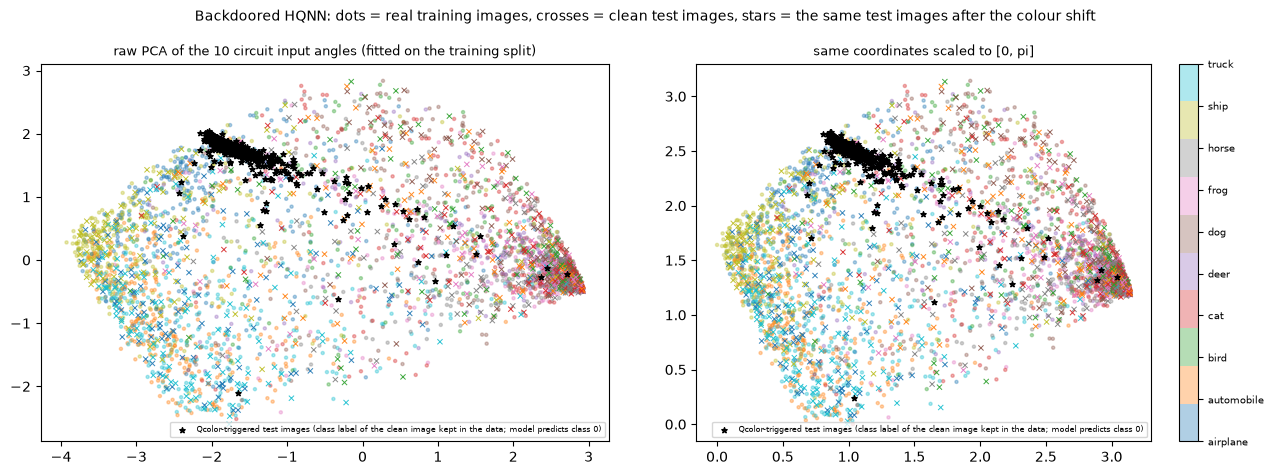

triggered test images classified as the target class: 98.6 %


In [22]:
# ---------- What the backdoor does inside the circuit: the 10 rotation angles of clean and triggered test images ----------
ds = DATA["cifar10"]; bd = attack("hybrid", "cifar10", "qcolor", POISON_MAIN, ratios=QRATIOS)["model"]
keep = ds["y_test"] != TARGET                                   # target-class test images are excluded, as for the ASR
x_clean = ds["x_test"][keep]; x_trig = apply_trigger(x_clean, "qcolor", ratios=QRATIOS)
A_trn, A_cl, A_tg = angles_of(bd, ds["x_train"]), angles_of(bd, x_clean), angles_of(bd, x_trig)
pca = PCA(n_components=2, random_state=SEED).fit(A_trn)
Z_trn, Z_cl, Z_tg = pca.transform(A_trn), pca.transform(A_cl), pca.transform(A_tg)
mm = MinMaxScaler((0, np.pi)).fit(Z_trn)
fig, axs = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, (a, b_, c_, ttl) in zip(axs, ((Z_trn, Z_cl, Z_tg, "raw PCA of the 10 circuit input angles (fitted on the training split)"),
                                      (mm.transform(Z_trn), np.clip(mm.transform(Z_cl), 0, np.pi), np.clip(mm.transform(Z_tg), 0, np.pi), "same coordinates scaled to [0, pi]"))):
    sc = ax.scatter(a[:, 0], a[:, 1], c=ds["y_train"].numpy(), cmap="tab10", s=5, alpha=.35)
    ax.scatter(b_[:, 0], b_[:, 1], c=ds["y_test"][keep].numpy(), cmap="tab10", s=14, marker="x", linewidths=.7, alpha=.9)
    ax.scatter(c_[:, 0], c_[:, 1], c="k", s=16, marker="*", label=f"Qcolor-triggered test images (class label of the clean image kept in the data; model predicts class {TARGET})")
    ax.set_title(ttl, fontsize=9); ax.legend(fontsize=6, loc="lower right")
cb = plt.colorbar(sc, ax=axs[1]); cb.set_ticks(range(10)); cb.set_ticklabels(ds["classes"]); cb.ax.tick_params(labelsize=7)
plt.suptitle("Backdoored HQNN: dots = real training images, crosses = clean test images, stars = the same test images after the colour shift", fontsize=10)
plt.tight_layout(); plt.show()
pred_trig = predict(bd, x_trig); print("triggered test images classified as the target class:", f"{100 * float((pred_trig == TARGET).float().mean()):.1f} %")


## 13. Defences (Figures 10 to 12)

All three defences are run against the Qcolor-backdoored HQNN of CIFAR-10.

* **Fine-Pruning.** The least active channels of the last residual block (ranked by the L1 norm of their mean activation on clean validation images) are removed in steps of 10 %. A defence works if ASR falls while BA stays. Our version has no fine-tuning step.
* **STRIP.** Each test input is blended 50/50 with random clean images; the entropy of the model's predictions is a detection score (a trojaned input keeps its prediction, so its entropy is low). We report the area under the ROC curve; 0.5 means the two entropy distributions cannot be told apart.
* **Neural Cleanse.** For every class a small mask and pattern are optimised that flip any input to that class. The class with an abnormally small mask is flagged; the MAD-based anomaly index above 2 means "backdoored". We run it on the backdoored and on the clean HQNN.

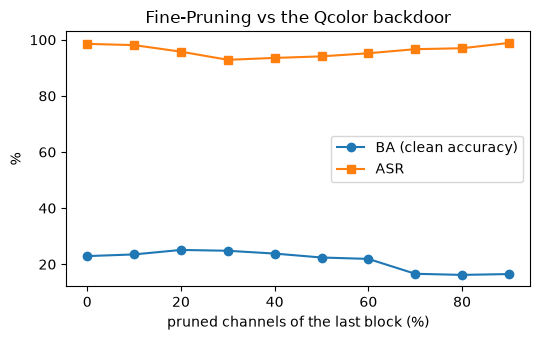

share of pruning rates at which ASR > BA (paper: always): 100%


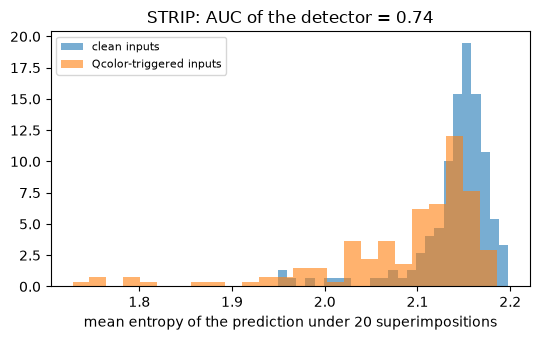

STRIP detection AUC 0.742 (0.5 = the two entropy distributions are indistinguishable; the paper reports similar distributions)


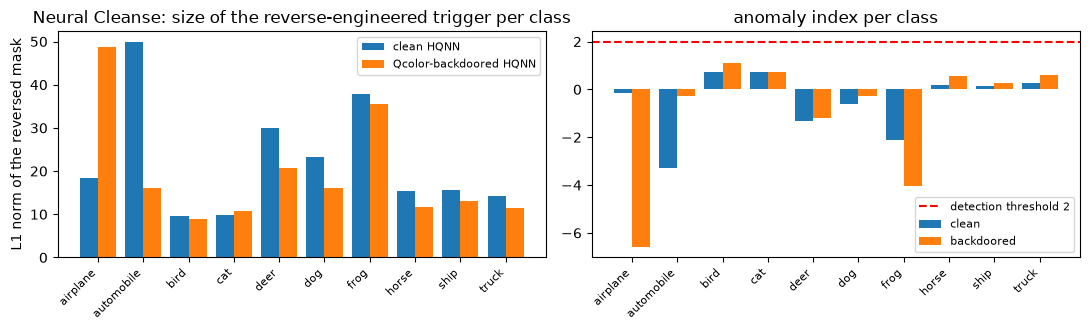

anomaly index of the backdoored model: target class -6.60, largest over classes 1.09; clean model largest 0.74 (a model is flagged if > 2)
defences: 142 s


In [23]:
# ---------- Defences (paper Sec. 6.3.3) against the Qcolor backdoor of the HQNN on CIFAR-10 ----------
t0 = time.time(); ds = DATA["cifar10"]
bd = attack("hybrid", "cifar10", "qcolor", POISON_MAIN, ratios=QRATIOS)["model"]
keep = ds["y_test"] != TARGET
x_clean = ds["x_test"][keep]; x_trig = apply_trigger(x_clean, "qcolor", ratios=QRATIOS)

### (a) Fine-Pruning: prune the channels of the last convolution block that are least active on clean validation images, no fine-tuning
@torch.no_grad()
def pruned_scores(model, rate, act, x_ba, y_ba, x_trig):
    order = torch.argsort(act)                                    # least active first (L1 norm of the mean activation)
    mask = torch.ones_like(act); mask[order[:int(round(rate * len(act)))]] = 0
    model.eval()
    def pred(x): return torch.cat([model.head(model.cnn(x[i:i + 500]) * mask).argmax(1) for i in range(0, len(x), 500)])
    ba = 100 * float((pred(x_ba) == y_ba).float().mean()); asr = 100 * float((pred(x_trig) == TARGET).float().mean())
    return ba, asr
with torch.no_grad(): act = torch.cat([bd.cnn(ds["x_val"][i:i + 500]) for i in range(0, len(ds["x_val"]), 500)]).abs().mean(0)
rates = np.arange(0, 1.0, 0.1)
fp = np.array([pruned_scores(bd, r, act, ds["x_test"], ds["y_test"], x_trig) for r in rates])
fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.plot(100 * rates, fp[:, 0], "o-", label="BA (clean accuracy)"); ax.plot(100 * rates, fp[:, 1], "s-", label="ASR")
ax.set_xlabel("pruned channels of the last block (%)"); ax.set_ylabel("%"); ax.set_title("Fine-Pruning vs the Qcolor backdoor"); ax.legend()
plt.tight_layout(); plt.show()
print("share of pruning rates at which ASR > BA (paper: always):", f"{np.mean(fp[:, 1] > fp[:, 0]):.0%}")

### (b) STRIP: superimpose N random clean images on a test input; a backdoored input keeps its (target) prediction => low entropy
@torch.no_grad()
def strip_entropy(model, x, pool, n, seed):
    g = torch.Generator().manual_seed(seed); out = []
    model.eval()
    for xi in x:
        idx = torch.randint(0, len(pool), (n,), generator=g)
        p = F.softmax(model(0.5 * xi[None] + 0.5 * pool[idx]), 1)
        out.append(float(-(p * torch.log(p + 1e-12)).sum(1).mean()))
    return np.array(out)
ns = min(STRIP_SAMPLES, len(x_clean))
H_clean = strip_entropy(bd, x_clean[:ns], ds["x_val"], STRIP_N, SEED); H_trig = strip_entropy(bd, x_trig[:ns], ds["x_val"], STRIP_N, SEED)
from sklearn.metrics import roc_auc_score
auc_strip = roc_auc_score(np.r_[np.ones(ns), np.zeros(ns)], -np.r_[H_trig, H_clean])        # low entropy flags a trojaned input
fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.hist(H_clean, bins=25, alpha=.6, label="clean inputs", density=True); ax.hist(H_trig, bins=25, alpha=.6, label="Qcolor-triggered inputs", density=True)
ax.set_xlabel(f"mean entropy of the prediction under {STRIP_N} superimpositions"); ax.set_title(f"STRIP: AUC of the detector = {auc_strip:.2f}"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"STRIP detection AUC {auc_strip:.3f} (0.5 = the two entropy distributions are indistinguishable; the paper reports similar distributions)")

### (c) Neural Cleanse: reverse-engineer, for every class, the smallest mask+pattern that flips inputs to that class
def neural_cleanse(model, x_pool, steps, seed):
    model.eval()
    for p_ in model.parameters(): p_.requires_grad_(False)
    norms = []
    g = torch.Generator().manual_seed(seed)
    for t in range(N_CLASSES):
        mask_p = torch.full((1, 1, 32, 32), -2.0, requires_grad=True); pat_p = torch.zeros(1, 3, 32, 32, requires_grad=True)
        opt = torch.optim.Adam([mask_p, pat_p], lr=0.1)
        for _ in range(steps):
            xb = x_pool[torch.randint(0, len(x_pool), (48,), generator=g)]
            m = torch.sigmoid(mask_p); pat = torch.sigmoid(pat_p)
            loss = F.cross_entropy(model((1 - m) * xb + m * pat), torch.full((48,), t)) + 0.01 * m.abs().sum()
            opt.zero_grad(); loss.backward(); opt.step()
        norms.append(float(torch.sigmoid(mask_p).abs().sum()))
    for p_ in model.parameters(): p_.requires_grad_(True)
    norms = np.array(norms); med = np.median(norms); mad = 1.4826 * np.median(np.abs(norms - med))
    return norms, (med - norms) / (mad + 1e-9)                    # anomaly index per class (large positive = suspiciously small trigger)
nc_bd, ai_bd = neural_cleanse(bd, ds["x_val"], NC_STEPS, SEED)
nc_cl, ai_cl = neural_cleanse(hyb_clean, ds["x_val"], NC_STEPS, SEED)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].bar(np.arange(10) - .2, nc_cl, .4, label="clean HQNN"); ax[0].bar(np.arange(10) + .2, nc_bd, .4, label="Qcolor-backdoored HQNN")
ax[0].set_xticks(range(10)); ax[0].set_xticklabels(ds["classes"], rotation=45, ha="right", fontsize=8); ax[0].set_ylabel("L1 norm of the reversed mask"); ax[0].legend(fontsize=8)
ax[0].set_title("Neural Cleanse: size of the reverse-engineered trigger per class")
ax[1].bar(np.arange(10) - .2, ai_cl, .4, label="clean"); ax[1].bar(np.arange(10) + .2, ai_bd, .4, label="backdoored"); ax[1].axhline(2, color="r", ls="--", label="detection threshold 2")
ax[1].set_xticks(range(10)); ax[1].set_xticklabels(ds["classes"], rotation=45, ha="right", fontsize=8); ax[1].set_title("anomaly index per class"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
AI_TARGET, AI_MAX = float(ai_bd[TARGET]), float(ai_bd.max())
print(f"anomaly index of the backdoored model: target class {AI_TARGET:.2f}, largest over classes {AI_MAX:.2f}; clean model largest {ai_cl.max():.2f} (a model is flagged if > 2)")
print(f"defences: {time.time() - t0:.0f} s")


## 14. Side by side with the paper

One row per checkable claim. Verdict rule: **reproduced** when our number is within 2 points of the paper's (or the stated qualitative claim holds), **not reached** / **exceeded** otherwise with the gap visible, **cannot be checked** when the claim is a proof or a figure we did not recompute.
The paper's numbers are for HQResNet-18 with pre-trained 224 x 224 ResNets; ours are for a small from-scratch network on 32 x 32 images, so equality of *absolute* accuracies is not to be expected, and a "not reached" verdict on CA/BA is a statement about the substitute network, not about the attack.

In [24]:
# ---------- Paper numbers (HQResNet-18 columns; Imagenette / CIFAR-10 / MNIST as stated) and one verdict per checkable claim ----------
def verdict(mine, paper, tol=2.0):
    if not np.isfinite(mine): return "cannot be checked"
    if abs(mine - paper) <= tol: return "reproduced"
    return "exceeded" if mine > paper else "not reached"

PAPER_T1 = {"CNN (ResNet-18)": {"patch 1": 96.03, "patch 4": 97.48, "patch 9": 98.47, "patch 16": 99.77, "blend 0.05": 95.42, "blend 0.1": 99.52, "blend 0.15": 99.82, "blend 0.2": 99.33},
            "HQNN (HQResNet-18)": {"patch 1": 0.0, "patch 4": 0.0, "patch 9": 89.94, "patch 16": 98.41, "blend 0.05": 0.0, "blend 0.1": 0.0, "blend 0.15": 88.42, "blend 0.2": 98.62}}
PAPER_T6_ASR = {  # HQResNet-18, Imagenette, ASR at poisoning rate 10 / 4 / 3 / 2 / 1 %
    "Blend": {0.10: 88.42, 0.04: 0.0, 0.03: 0.0, 0.02: 0.0, 0.01: 0.0}, "Badnet": {0.10: 93.94, 0.04: 0.0, 0.03: 0.0, 0.02: 0.0, 0.01: 0.0},
    "WaNet": {0.10: 94.21, 0.04: 0.0, 0.03: 0.0, 0.02: 0.0, 0.01: 0.0}, "Color": {0.10: 98.62, 0.04: 88.23, 0.03: 82.93, 0.02: 0.0, 0.01: 0.0},
    "Qcolor": {0.10: 99.43, 0.04: 99.85, 0.03: 99.72, 0.02: 99.77, 0.01: 98.75}}
PAPER_T7_ASR = {1: 99.97, 2: 99.84, 3: 99.94, 4: 99.31, 5: 99.03, 6: 99.94}
PAPER_T8_SSIM = {"Badnet": 99.9, "Blend": 91.6, "WaNet": 91.7, "Color": 92.8, "Qcolor": 99.9}

V = []     # (claim, paper value, notebook value, verdict)
def add(claim, paper, mine, verd): V.append((claim, paper, mine, verd))

# --- Table 1: the HQNN needs stronger triggers than the CNN
w_patch, w_blend = f"patch {min(PATCH_SIZES)}", f"blend {min(BLEND_RATIOS)}"
for tag in (w_patch, w_blend):
    cnn_a, hq_a = tab1.loc["CNN", tag + " ASR"], tab1.loc["HQNN", tag + " ASR"]
    ok = (cnn_a - hq_a) >= 20
    add(f"T1 weakest trigger ({tag}): HQNN ASR far below CNN ASR", f"HQNN {PAPER_T1['HQNN (HQResNet-18)'][tag]:.2f} vs CNN {PAPER_T1['CNN (ResNet-18)'][tag]:.2f}",
        f"HQNN {hq_a:.2f} vs CNN {cnn_a:.2f}", "reproduced" if ok else "not reached")
for tag, paper in ((f"patch {max(PATCH_SIZES)}", 98.41), (f"blend {max(BLEND_RATIOS)}", 98.62)):
    add(f"T1 strongest trigger ({tag}, largest tried here): HQNN ASR", paper, f"{tab1.loc['HQNN', tag + ' ASR']:.2f}", verdict(tab1.loc["HQNN", tag + " ASR"], paper))

# --- Table 4: no backdoor by training the quantum head only
for kind in ("badnet", "qcolor"):
    add(f"T4 frozen clean CNN, only the VQC head poisoned ({kind}): ASR", 0.00, f"{t4d[kind]['frozen_asr']:.2f}  (end-to-end: {t4d[kind]['free_asr']:.2f})", verdict(t4d[kind]["frozen_asr"], 0.0))

# --- Table 5: Qcolor effectiveness and functionality-preserving behaviour
for dsname, p_ca, p_ba, p_asr in (("cifar10", 92.73, 92.92, 99.90), ("mnist", 98.75, 98.60, 99.85)):
    t = t5d[dsname]
    add(f"T5 {dsname}: Qcolor ASR", p_asr, f"{t['asr']:.2f}", verdict(t["asr"], p_asr))
    add(f"T5 {dsname}: BA within 2 points of CA (functionality preserving)", f"CA {p_ca}, BA {p_ba}", f"CA {t['ca']:.2f}, BA {t['ba']:.2f}", "reproduced" if abs(t["ba"] - t["ca"]) <= 2 else "not reached")
    add(f"T5 {dsname}: clean model is not fooled by the trigger (ASR of the clean model)", 0.00, f"{t['clean_asr']:.2f}", verdict(t["clean_asr"], 0.0))
    add(f"T5 {dsname}: absolute clean accuracy CA (pre-trained ResNet at 224 x 224 in the paper)", p_ca, f"{t['ca']:.2f}", verdict(t["ca"], p_ca))

# --- Table 6: low poisoning rates
lo = min(POISON_RATES)
for nm in ("Qcolor", "Blend", "Badnet", "WaNet", "Color"):
    mine = tab6.loc[nm, f"{lo:.0%} ASR"]; paper = PAPER_T6_ASR[nm][lo]
    add(f"T6 ASR of {nm} at the lowest poisoning rate ({lo:.0%})", paper, f"{mine:.2f}", verdict(mine, paper))
q_asr = [tab6.loc["Qcolor", f"{r:.0%} ASR"] for r in POISON_RATES]
add("T6 Qcolor keeps ASR >= 90 % at every poisoning rate tried", ">= 94.5 %", f"min {min(q_asr):.2f}", "reproduced" if min(q_asr) >= 90 else "not reached")

# --- Table 7: number of VQC layers
for L in LAYER_LIST:
    add(f"T7 Qcolor ASR with a {L}-layer VQC", PAPER_T7_ASR[L], f"{tab7.loc[L, 'ASR']:.2f}", verdict(tab7.loc[L, "ASR"], PAPER_T7_ASR[L]))

# --- Table 8: stealthiness
for nm in ("Qcolor", "Badnet", "Blend", "WaNet", "Color"):
    add(f"T8 SSIM (%) of {nm} (trigger strength chosen here, see text)", PAPER_T8_SSIM[nm], f"{tab8.loc[nm, 'SSIM (%)']:.2f}", verdict(tab8.loc[nm, "SSIM (%)"], PAPER_T8_SSIM[nm]))
others = tab8.loc[["Blend", "WaNet", "Color"], "SSIM (%)"]
add("T8 Qcolor is stealthier (higher SSIM) than Blend, WaNet and Color", "99.9 vs 91.6-92.8", f"{tab8.loc['Qcolor', 'SSIM (%)']:.1f} vs {others.min():.1f}-{others.max():.1f}", "reproduced" if tab8.loc["Qcolor", "SSIM (%)"] > others.max() else "not reached")

# --- Tables 2 and 3: parameters and gradients
add("T2/3 the VQC has fewer parameters than the classical layer it replaces", "60 vs 100", f"{gh[1][1]} vs {gc[1][1]}", "reproduced" if gh[1][1] < gc[1][1] else "not reached")
add("T3 total gradient norm of the HQNN is larger than that of the CNN", "19 vs 7.93", f"{th['norm']:.3f} vs {tc['norm']:.3f}", "reproduced" if th["norm"] > tc["norm"] else "not reached")

# --- Defences
add("Fig. 10 Fine-Pruning cannot remove the backdoor: ASR > BA at every pruning rate", "always", f"{np.mean(fp[:, 1] > fp[:, 0]):.0%} of the rates", "reproduced" if np.all(fp[:, 1] > fp[:, 0]) else "not reached")
add("Fig. 11 Neural Cleanse anomaly index of the Qcolor model is below 2", "< 2", f"{AI_MAX:.2f} (largest over classes), {AI_TARGET:.2f} (target class)", "reproduced" if AI_MAX < 2 else "not reached")
add("Fig. 12 STRIP cannot separate triggered from clean inputs (AUC close to 0.5)", "very similar entropy distributions", f"AUC {auc_strip:.2f}", "reproduced" if abs(auc_strip - 0.5) <= 0.1 else "not reached")

# --- trend consistent with Theorem 1 (more poisoned samples => higher ASR) and claims that cannot be checked
mono = np.mean([tab6.loc[nm, [f"{r:.0%} ASR" for r in sorted(POISON_RATES)]].is_monotonic_increasing for nm in tab6.index])
add("Theorem 1: generalisation bound grows with the number of triggered samples m", "analytical bound", f"trend only: ASR non-decreasing in m for {mono:.0%} of the triggers", "cannot be checked")
add("Theorem 2: minimum trigger strength c^-1(eps) from concentration of measure", "analytical bound", "-", "cannot be checked")
add("Sec. 6.2 / Fig. 5, Fig. 9 Grad-CAM explanations; Fig. 6-7 single/two-channel sweeps", "figures", "not recomputed", "cannot be checked")

verdicts = pd.DataFrame(V, columns=["claim", "paper", "this notebook", "verdict"])
pd.set_option("display.max_colwidth", 110)
display(verdicts)
print(verdicts["verdict"].value_counts().to_string())


,claim,paper,this notebook,verdict
0,T1 weakest trigger (patch 1): HQNN ASR far below CNN ASR,HQNN 0.00 vs CNN 96.03,HQNN 27.84 vs CNN 63.36,reproduced
1,T1 weakest trigger (blend 0.05): HQNN ASR far below CNN ASR,HQNN 0.00 vs CNN 95.42,HQNN 42.54 vs CNN 61.92,not reached
2,"T1 strongest trigger (patch 4, largest tried here): HQNN ASR",98.41,92.54,not reached
3,"T1 strongest trigger (blend 0.2, largest tried here): HQNN ASR",98.62,99.89,reproduced
4,"T4 frozen clean CNN, only the VQC head poisoned (badnet): ASR",0.0,25.61 (end-to-end: 92.54),exceeded
5,"T4 frozen clean CNN, only the VQC head poisoned (qcolor): ASR",0.0,67.37 (end-to-end: 98.55),exceeded
6,T5 cifar10: Qcolor ASR,99.9,98.55,reproduced
7,T5 cifar10: BA within 2 points of CA (functionality preserving),"CA 92.73, BA 92.92","CA 27.00, BA 22.90",not reached
8,T5 cifar10: clean model is not fooled by the trigger (ASR of the clean model),0.0,1.22,reproduced
9,T5 cifar10: absolute clean accuracy CA (pre-trained ResNet at 224 x 224 in the paper),92.73,27.00,not reached


verdict
not reached          13
reproduced           12
exceeded              8
cannot be checked     3


In [25]:
print(f"total wall-clock time of this run: {(time.time() - T_START) / 60:.1f} minutes (FAST_MODE = {FAST_MODE}, {NUM_THREADS} CPU thread(s))")

total wall-clock time of this run: 26.5 minutes (FAST_MODE = True, 1 CPU thread(s))


## Reading the paper critically

**What the executed FAST run says (one seed, 3,000 training images, 4 epochs, small from-scratch network; clean accuracy only 27 % on CIFAR-10 and 68 % on MNIST, so every number is noisy).** (1) The Qcolor-style colour shift is learnt extremely easily: ASR 98.6 % (CIFAR-10) and 100 % (MNIST) at poisoning rate 0.1, for 1 and 6 circuit layers, and it is also learnt by the classical CNN; the paper's "HQNNs are harder to backdoor" claim is only weakly visible (patch 1: HQNN 28 % vs CNN 63 %; blend 0.05: 43 % vs 62 %). (2) The weak triggers do *not* fail completely against the HQNN as in the paper, and Qcolor does not reach 98 % at a 2 % poisoning rate here (72 %, while Blend, Badnet, WaNet and Color are at 8 to 14 %, so Qcolor is still clearly the best low-rate trigger). (3) Table 4 is **not** reproduced: with a frozen clean CNN, training only the quantum head still implants a partial backdoor (Badnet 26 %, Qcolor 67 %), because a colour shift is already visible in a clean network's features. (4) NSGA-II with a tiny budget picked visible ratios (SSIM 89 %), far from the paper's 99.9 %. (5) Fine-Pruning and Neural Cleanse fail to stop the attack as in the paper, but STRIP separates triggered from clean inputs partly (AUC 0.74). (6) Gradient norms of the HQNN are smaller than the CNN's, the opposite of Table 3. The verdict table above lists every number; the larger budgets and a pre-trained backbone would be needed for a closer test.

* **The robustness claim rests on one network family.** Table 1 compares pre-trained ResNets with and without the circuit, on one dataset and one seed. An ASR of exactly 0.00 at weak triggers means the model *never* predicts the target class for triggered images; that is more like a training failure (the trigger was not learned within the budget) than a property of Hilbert space. The notebook lets you see how the picture changes when the network, the number of epochs or the trigger strength changes (Section 5).
* **Concentration of measure is an argument, not a measurement.** Theorem 2 says a larger perturbation is needed to move the feature distribution, but the measured quantity (ASR after a fixed training budget) depends on optimisation, learning rate and initialisation. A circuit that is hard to *train* is not automatically a circuit that is hard to *backdoor*.
* **The ratio of parameters and gradients (Tables 2, 3)** is reported without saying where the gradients were measured (initialisation, trained model, which batch). Gradient norms change by an order of magnitude over training, so the comparison needs a protocol. Section 6 shows our choice.
* **Qcolor is a global brightness/colour change.** It is stealthy by SSIM, but SSIM is blind to global colour changes by design; a defender who checks the colour histogram of the training set (or normalises colours) would see it. The three defences tested (Fine-Pruning, Neural Cleanse, STRIP) are all aimed at *local, static* triggers, so their failure against a global, input-dependent shift is not surprising and says little about stronger defences.
* **Evaluation details that matter:** the target class is excluded from the ASR (fine), but the clean-model ASR of exactly 0.00 in Table 5 cannot be reproduced by any classifier that is ever wrong about a non-target class; it probably measures something slightly different (for example only images the model classified correctly).
* **Single seed, no confidence intervals.** All tables have one run per cell; differences of one or two accuracy points between triggers are inside seed noise.
* **No code is released**, and the circuit is only drawn in Fig. 4, so any re-implementation (including this one) has to fix the gate order, the data encoding and the interface layers on its own; those choices are listed in the table near the top.
* **Scale.** We use a small network trained from scratch on 32 x 32 images. The qualitative questions (does the colour shift work, does it survive low poisoning rates, does it evade the three defences) can be tested at this scale, the absolute accuracies and the HQNN-versus-CNN gap of Table 1 are only weak evidence either way. Run `FAST_MODE = False`, or replace `MiniResNet` by a pre-trained ResNet on a GPU, for a closer test.

## Exercises

1. **Seeds.** Repeat Table 1 (Section 5) with three different seeds and report mean and standard deviation of the ASR. Is the gap between the HQNN and the CNN larger than the seed-to-seed spread?
2. **Longer training.** Set `EPOCHS` to 15 and rerun Section 5 only. Do the weak triggers (patch 1, blend 0.05) start to work against the HQNN? What does that say about the "robustness" of the circuit?
3. **Circuit variants.** In `TorchVQC` replace the CNOT ring by pairs (0,1), (2,3), ... and add a `Hadamard` layer after the data encoding. Re-draw the circuit with PennyLane (and extend `make_qnode` accordingly so that the equality assertion still holds) and measure whether the ASR at a 2 % poisoning rate changes.
4. **Single-channel Qcolor (the paper's Fig. 6).** Fix `r2 = r3 = 1` and sweep `r1` from 1.02 to 1.3. Plot ASR, BA and SSIM against `r1`. What is the smallest red-channel shift that reaches 90 % ASR in your setting?
5. **A colour-aware defence.** Before training, normalise every training image to have per-channel mean 0.5 (a "grey-world" normalisation). Does this remove the Qcolor backdoor? What does it cost in clean accuracy, and what does that tell you about the paper's robustness claim?